# Auckland Property Price Prediction -- Exploratory Data Analysis

Data: `cache/dvrs_with_team_external.parquet`. This combines Auckland
Council sales data with our external features: location, flood risk,
zoning, noise, SA2 building consents, and distance to supermarkets/bus
stops.

This notebook only explores the data -- no filtering or modeling yet.

## 1. Import data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 70)

df = pd.read_parquet("./cache/dvrs_with_team_external.parquet")
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Loaded 92,010 rows, 56 columns


,valuation_roll_number,valuation_number_assessment,valuation_number_suffix,sale_date,district_code,sale_type,sales_group,sale_tenure,price_value_relationship,sale_price_gross,sale_price_net,sale_price_chattels,sale_price_other,capital_value,land_value,current_effective_valuation_date,situation_number,additional_situation_number,situation_name,certificate_of_title,land_area,zoning,actual_property_use,units_of_use,off_street_parking,building_age_indicator,building_condition_indicator,building_construction_indicator,building_site_coverage,building_total_floor_area,property_category,legal_description,mass_contour,mass_view,mass_scope_of_view,mass_total_floor_area,mass_deck,mass_workshop_laundry,mass_other_improvements,mass_garage_under_main_roof,mass_garage_freestanding,valuation_id_concat,longitude,latitude,in_flood_plain,in_flood_sensitive_area,dist_to_flood_plain_m,dist_to_flood_sensitive_area_m,unitary_plan_zone,linz_matched,walk_supermarket_network_m,walk_bus_stop_network_m,drive_supermarket_network_m,drive_bus_stop_network_m,noise_category_combination,sa2_new_dwellings_consented_12m
0,1,2501710000,NaN,25022026,14,S,701,1,1,1514000,1499000,15000,0,1400000,1025000,45413,166,NaN,Point Chevalier RD,335510,0,9C,91,1,1,192,GG,WI,80,87,RD192A,"Carport 1 DP 384040, Flat 1 DP 384040,",LV,N,N,87,Y,N,N,0,1,1_2501710000,174.706389,-36.865688,False,False,241.910185,4866.407069,60.0,True,1578.192284,54.442135,535.386978,0.000000,outside_current_overlay,20
1,1,2600010100,NaN,1042025,14,S,701,1,1,1515112,1507112,8000,0,1675000,1500000,44348,7,NaN,Montrose ST,NA118D/908,0.0403,9D,91,1,0,193,AA,WT,120,117,RD193B,Lot 2 DP 189123 403m2,LV,N,N,117,Y,N,N,0,0,1_2600010100,174.708779,-36.869417,False,False,194.452135,4614.989420,8.0,True,309.197383,173.432349,134.495189,155.505174,outside_current_overlay,7
2,1,4300000201,NaN,14022025,14,S,701,1,1,1622800,1609800,13000,0,1650000,1360000,44348,5,NaN,St Michaels AV,NA57C/301,0,9C,91,1,1,198,AA,WT,60,124,RD198B,"Flat 3 DP 103999, Lot 4 DP 7475 652m2",LV,N,N,124,Y,N,N,1,0,1_4300000201,174.702890,-36.861304,False,False,199.900952,4667.722058,60.0,True,1720.397633,68.370379,1122.801352,9.608944,outside_current_overlay,3
3,1,4300110000,NaN,17012025,14,S,701,1,1,2105000,2092000,13000,0,2600000,2325000,44348,35,NaN,St Michaels AV,NA405/218,0.0656,9B,91,1,1,193,AA,WT,120,123,RD193B,Lot 2 DP 15494 656m2,EF,N,N,123,Y,N,N,0,0,1_4300110000,174.700846,-36.862339,False,False,18.820703,4814.776819,18.0,True,1981.946279,329.919025,1502.064675,333.383823,outside_current_overlay,11
4,1,4300270001,NaN,11112025,14,S,701,1,2,1875000,1862000,13000,0,2300000,2025000,45413,66,NaN,St Michaels AV,115395,0.0396,9B,91,1,1,192,AA,WI,137,124,RD192B,Lot 1 DP 328302 396m2,EF,W,M,109,Y,N,N,1,0,1_4300270001,174.698847,-36.863616,False,False,6.764028,4804.594688,18.0,True,2224.730646,465.392323,1606.980701,493.788293,outside_current_overlay,9


### 1.1 Remove leakage columns

- `sale_price_net`, `sale_price_chattels`, `sale_price_other`: these add up
  to the target price, so keeping them would be cheating.
- `capital_value`, `land_value`: the council's own valuation, not a real
  property feature. Keeping it would let the model copy an existing price
  estimate instead of learning from the data.

All five are removed before any analysis.

In [2]:
df = df.drop(columns=[
    "sale_price_net", "sale_price_chattels", "sale_price_other",
    "capital_value", "land_value",
])
print(f"Dropped sale_price_net/chattels/other, capital_value, land_value. {df.shape[1]} columns remain.")


Dropped sale_price_net/chattels/other, capital_value, land_value. 51 columns remain.


In [3]:
df.dtypes.to_frame("dtype")

,dtype
valuation_roll_number,str
valuation_number_assessment,str
valuation_number_suffix,str
sale_date,str
district_code,str
sale_type,str
sales_group,str
sale_tenure,str
price_value_relationship,str
sale_price_gross,str


## 2. Data overview

Many columns are stored as text even though they're numbers. Missing
values are shown below first.

In [4]:
missing = df.isna().mean().sort_values(ascending=False) * 100
missing = missing[missing > 0]
print(f"{len(missing)} / {df.shape[1]} columns have at least one missing value\n")
missing.round(2)

31 / 51 columns have at least one missing value



valuation_number_suffix             84.62
additional_situation_number         72.29
mass_other_improvements              7.85
mass_workshop_laundry                7.73
building_condition_indicator         7.61
building_construction_indicator      7.45
mass_deck                            7.33
building_age_indicator               7.23
walk_supermarket_network_m           7.00
mass_view                            6.11
mass_scope_of_view                   6.11
walk_bus_stop_network_m              6.04
mass_contour                         5.98
drive_supermarket_network_m          5.46
drive_bus_stop_network_m             5.46
unitary_plan_zone                    4.45
latitude                             4.45
in_flood_sensitive_area              4.45
in_flood_plain                       4.45
sa2_new_dwellings_consented_12m      4.45
noise_category_combination           4.45
dist_to_flood_sensitive_area_m       4.45
dist_to_flood_plain_m                4.45
longitude                         

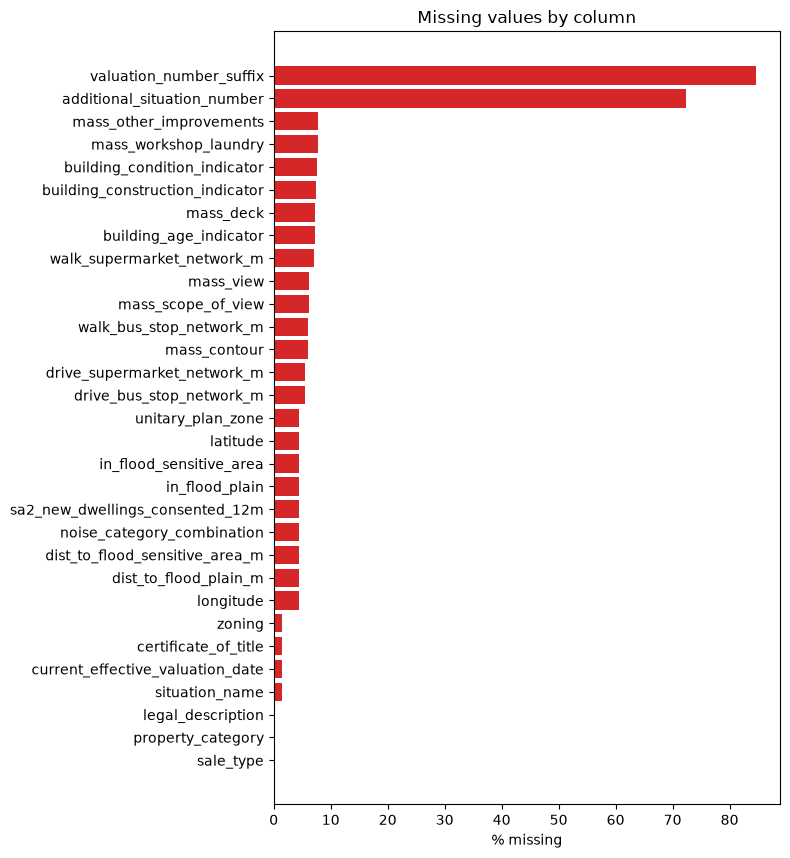

In [5]:
fig, ax = plt.subplots(figsize=(8, max(4, len(missing) * 0.28)))
ax.barh(missing.index[::-1], missing.values[::-1], color="tab:red")
ax.set_xlabel("% missing")
ax.set_title("Missing values by column")
plt.tight_layout()
plt.show()

## 3. Clean up data types

Convert text columns to numbers, and parse the sale date into a real date.

In [6]:
def parse_sale_date(s):
    if pd.isna(s):
        return pd.NaT
    s = str(s)
    year = int(s[-4:])
    month = int(s[-6:-4])
    day = int(s[:-6])
    return pd.Timestamp(year=year, month=month, day=day)


df["sale_date_parsed"] = df["sale_date"].apply(parse_sale_date)
df["current_effective_valuation_date_parsed"] = pd.to_datetime(
    pd.to_numeric(df["current_effective_valuation_date"], errors="coerce"), unit="D", origin="1899-12-30"
)

numeric_cols = [
    "sale_price_gross",
    "land_area", "building_total_floor_area",
    "mass_total_floor_area", "building_site_coverage", "off_street_parking",
    "units_of_use", "mass_garage_under_main_roof", "mass_garage_freestanding",
    "longitude", "latitude",
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Team-external numeric columns are already float/Int64, just need a plain float dtype
external_numeric_cols = [
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
    "sa2_new_dwellings_consented_12m",
]
for col in external_numeric_cols:
    df[col] = df[col].astype(float)

# Nullable boolean dtype: rows with no LINZ coordinate match (linz_matched=False)
# have None here, not True/False. Casting to "boolean" (not plain bool/object)
# makes `|` propagate that as NA instead of silently treating it as False.
for col in ["in_flood_plain", "in_flood_sensitive_area"]:
    df[col] = df[col].astype("boolean")

print("sale_date_parsed range:", df["sale_date_parsed"].min().date(), "to", df["sale_date_parsed"].max().date())
df[numeric_cols + external_numeric_cols].describe().T

sale_date_parsed range: 2024-01-01 to 2026-08-21


,count,mean,std,min,25%,50%,75%,max
sale_price_gross,92010.0,2.616173e+06,3.899396e+07,1.000000,755000.000000,1000000.000000,1.450000e+06,1.792507e+09
land_area,92010.0,2.580082e-01,4.050016e+00,0.000000,0.000000,0.028650,6.650000e-02,4.820000e+02
building_total_floor_area,92010.0,2.254900e+02,4.633720e+03,0.000000,86.000000,127.000000,1.850000e+02,3.900000e+05
mass_total_floor_area,92010.0,1.157855e+02,7.865629e+01,0.000000,77.000000,108.000000,1.520000e+02,4.888000e+03
building_site_coverage,92010.0,1.322485e+02,2.103515e+03,0.000000,59.000000,94.000000,1.370000e+02,6.000600e+05
off_street_parking,92010.0,1.570775e+00,7.167405e+00,0.000000,0.000000,1.000000,2.000000e+00,9.800000e+02
units_of_use,92010.0,1.049125e+00,7.697022e-01,0.000000,1.000000,1.000000,1.000000e+00,1.550000e+02
mass_garage_under_main_roof,92010.0,7.599826e-01,9.464774e-01,0.000000,0.000000,0.000000,2.000000e+00,5.600000e+01
mass_garage_freestanding,92010.0,3.416368e-01,6.970015e-01,0.000000,0.000000,0.000000,0.000000e+00,2.000000e+01
longitude,87916.0,1.747796e+02,1.158947e-01,174.234241,174.700457,174.765891,1.748747e+02,1.755077e+02


## 4. Target variable: `sale_price_gross`

Prices are right-skewed (a few very expensive sales). `log1p` fixes this
and is used later.

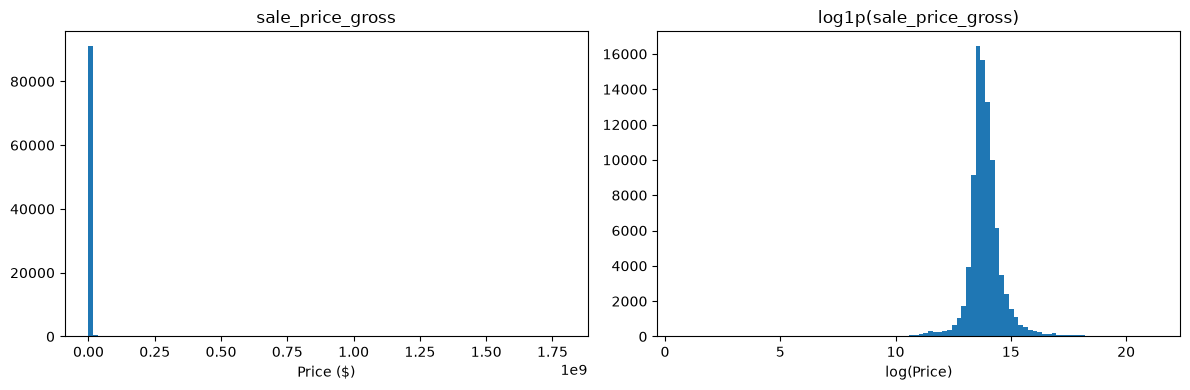

count    9.201000e+04
mean     2.616173e+06
std      3.899396e+07
min      1.000000e+00
25%      7.550000e+05
50%      1.000000e+06
75%      1.450000e+06
max      1.792507e+09
Name: sale_price_gross, dtype: float64

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["sale_price_gross"].dropna(), bins=100)
axes[0].set_title("sale_price_gross")
axes[0].set_xlabel("Price ($)")

axes[1].hist(np.log1p(df["sale_price_gross"].dropna()), bins=100)
axes[1].set_title("log1p(sale_price_gross)")
axes[1].set_xlabel("log(Price)")

plt.tight_layout()
plt.show()

df["sale_price_gross"].describe()

## 5. Fields used for filtering later

These five fields are used to filter the data in the modeling section.
Shown here unfiltered for context.

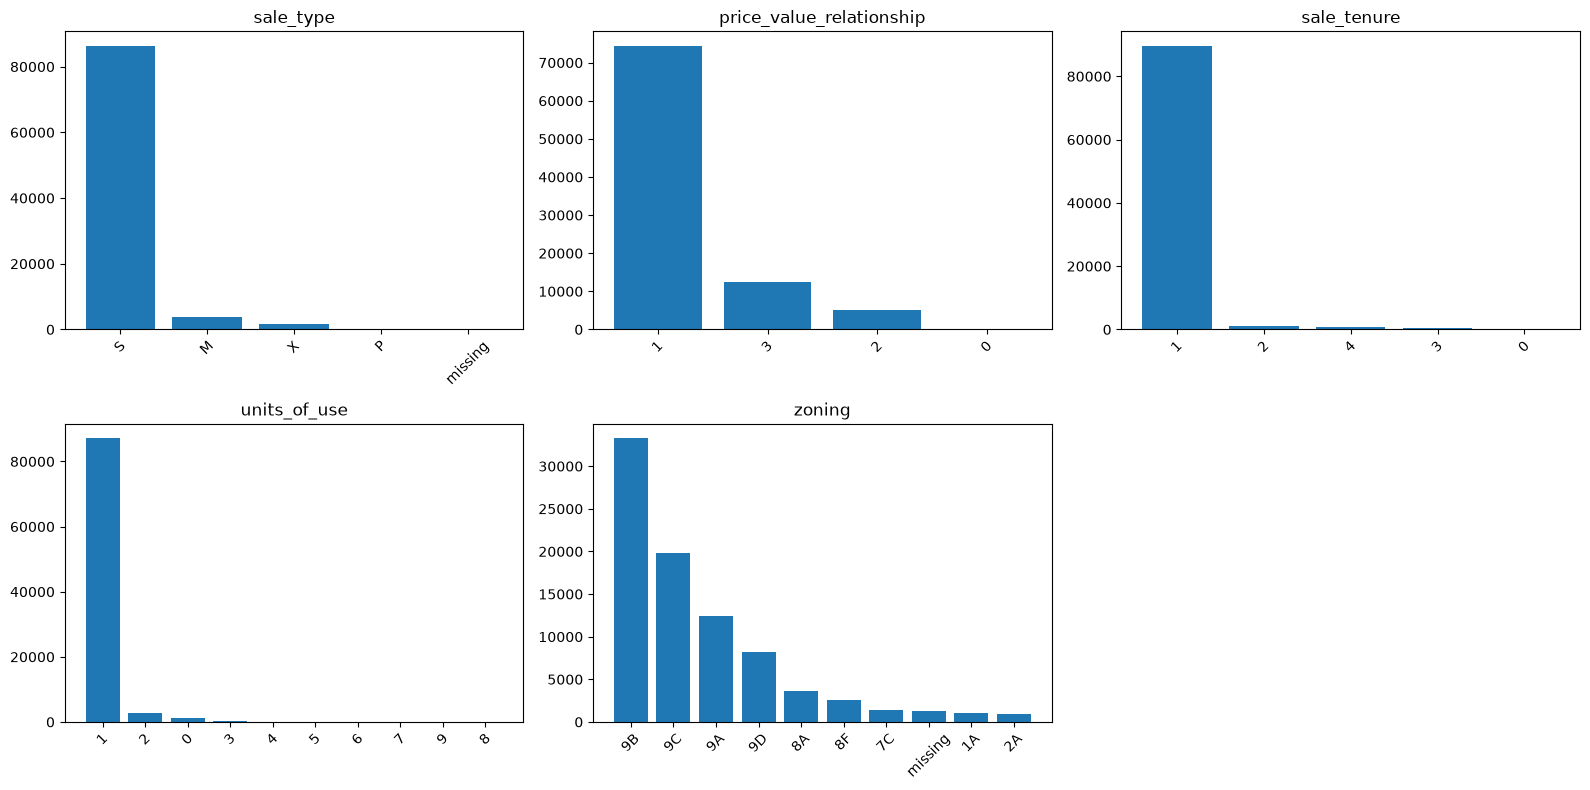


sale_type:
sale_type
S          86433
M           3900
X           1658
P             18
missing        1
Name: count, dtype: int64

price_value_relationship:
price_value_relationship
1    74490
3    12397
2     5077
0       46
Name: count, dtype: int64

sale_tenure:
sale_tenure
1    89730
2     1074
4      633
3      571
0        2
Name: count, dtype: int64

units_of_use:
units_of_use
1    87207
2     2903
0     1275
3      279
4      111
5       56
6       48
7       31
Name: count, dtype: int64


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, col, note in zip(axes.ravel(), [
    "sale_type", "price_value_relationship", "sale_tenure",
    "units_of_use", "zoning",
], ["", "", "", "", ""]):
    vc = df[col].fillna("missing").astype(str).value_counts(dropna=False).head(10)
    ax.bar(vc.index.astype(str), vc.values)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

for col in ["sale_type", "price_value_relationship", "sale_tenure", "units_of_use"]:
    print(f"\n{col}:")
    print(df[col].fillna("missing").astype(str).value_counts(dropna=False).head(8))

In [9]:
print("zoning, first character grouped (9=residential, 1=rural, 2=lifestyle per Council coding):")
print(df["zoning"].astype(str).str[0].value_counts(dropna=False).sort_index())
print()
print("linz_matched (new LINZ linkage found a coordinate):", df["linz_matched"].value_counts(dropna=False).to_dict())

zoning, first character grouped (9=residential, 1=rural, 2=lifestyle per Council coding):
zoning
0        473
1       1857
2       1249
3        181
4        190
5         84
6          1
7       1880
8       7854
9      76964
NaN     1277
Name: count, dtype: int64

linz_matched (new LINZ linkage found a coordinate): {True: 87916, False: 4094}


## 6. Numeric feature distributions

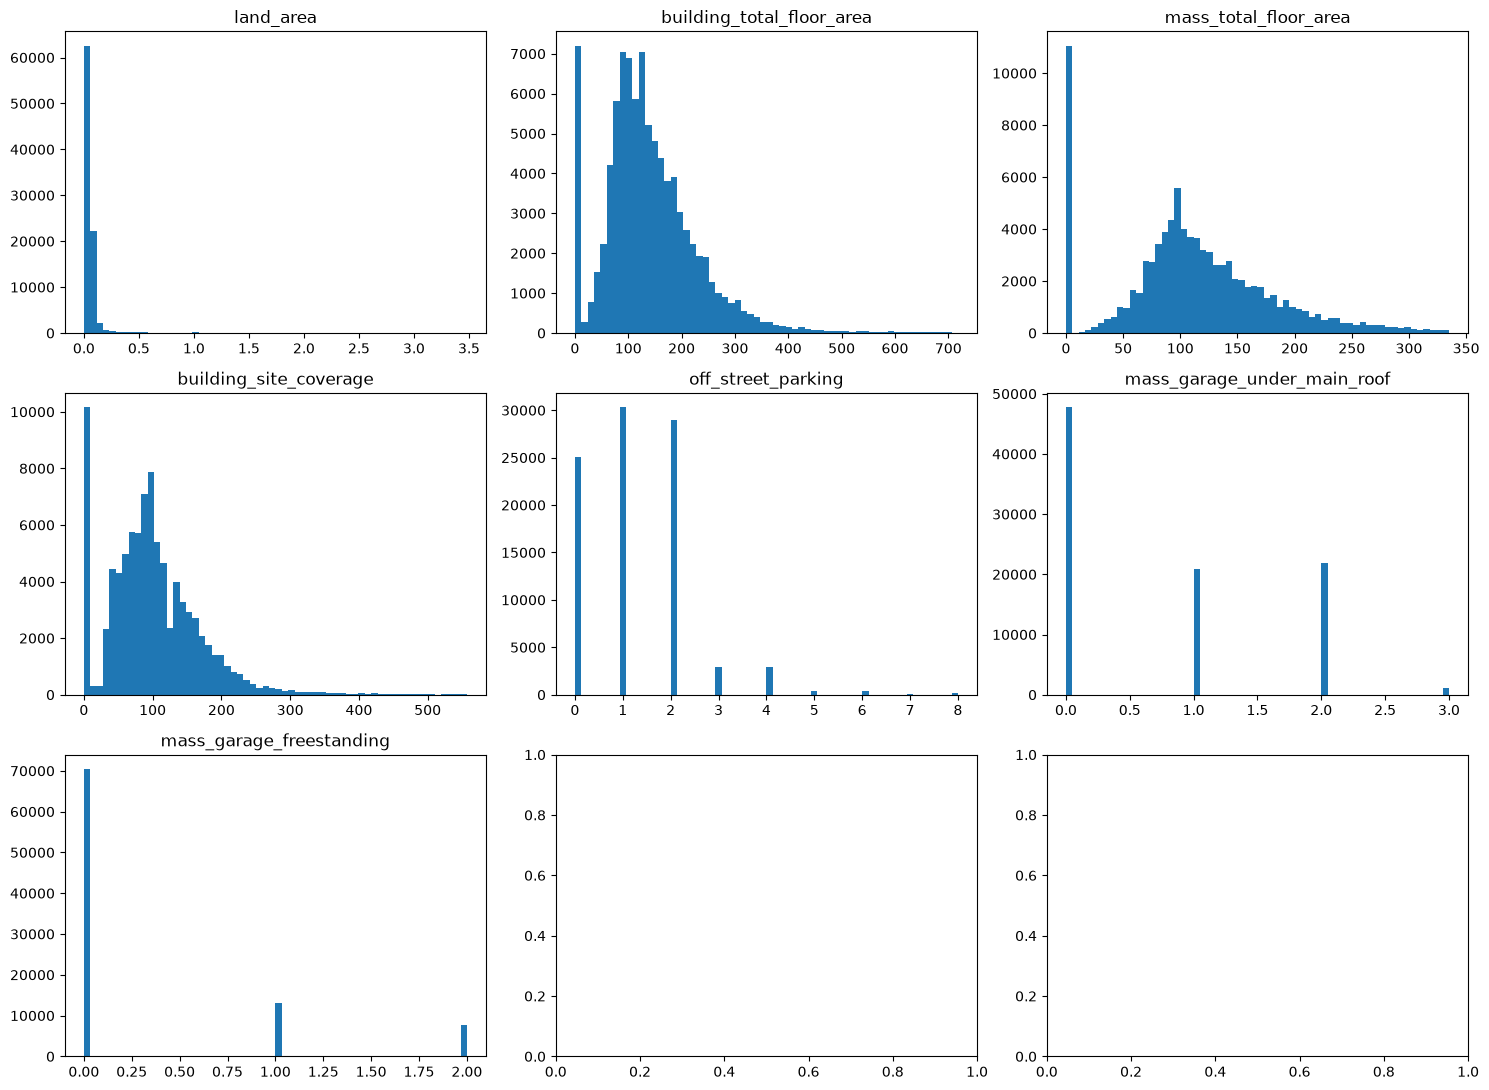

In [10]:
hist_cols = [
    "land_area", "building_total_floor_area",
    "mass_total_floor_area", "building_site_coverage", "off_street_parking",
    "mass_garage_under_main_roof", "mass_garage_freestanding",
]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), hist_cols):
    vals = df[col].dropna()
    vals = vals[vals <= vals.quantile(0.99)]  # trim extreme tail just for readability
    ax.hist(vals, bins=60)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 7. Numeric feature correlations with price

sale_price_gross                   1.000
off_street_parking                 0.331
building_site_coverage             0.099
building_total_floor_area          0.050
longitude                          0.021
land_area                          0.014
drive_supermarket_network_m        0.013
walk_supermarket_network_m         0.011
dist_to_flood_plain_m              0.006
drive_bus_stop_network_m          -0.003
walk_bus_stop_network_m           -0.003
dist_to_flood_sensitive_area_m    -0.006
latitude                          -0.009
sa2_new_dwellings_consented_12m   -0.014
mass_garage_freestanding          -0.016
mass_garage_under_main_roof       -0.023
mass_total_floor_area             -0.037
Name: sale_price_gross, dtype: float64


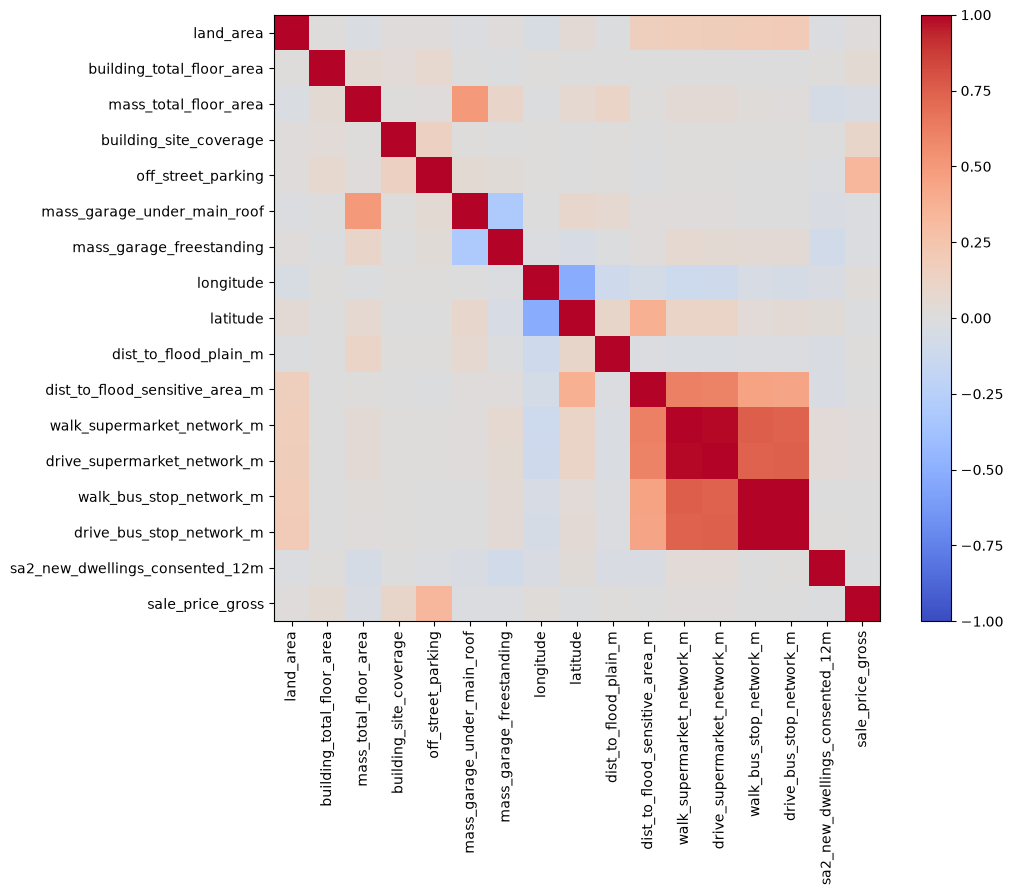

In [11]:
corr_cols = [
    "land_area", "building_total_floor_area",
    "mass_total_floor_area", "building_site_coverage", "off_street_parking",
    "mass_garage_under_main_roof", "mass_garage_freestanding",
    "longitude", "latitude", "dist_to_flood_plain_m", "dist_to_flood_sensitive_area_m",
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
    "sa2_new_dwellings_consented_12m",
]
corr_matrix = df[corr_cols + ["sale_price_gross"]].corr()
print(corr_matrix["sale_price_gross"].sort_values(ascending=False).round(3))

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
labels = list(corr_matrix.columns)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
plt.colorbar(im)
plt.tight_layout()
plt.show()

## 8. Categorical features vs price

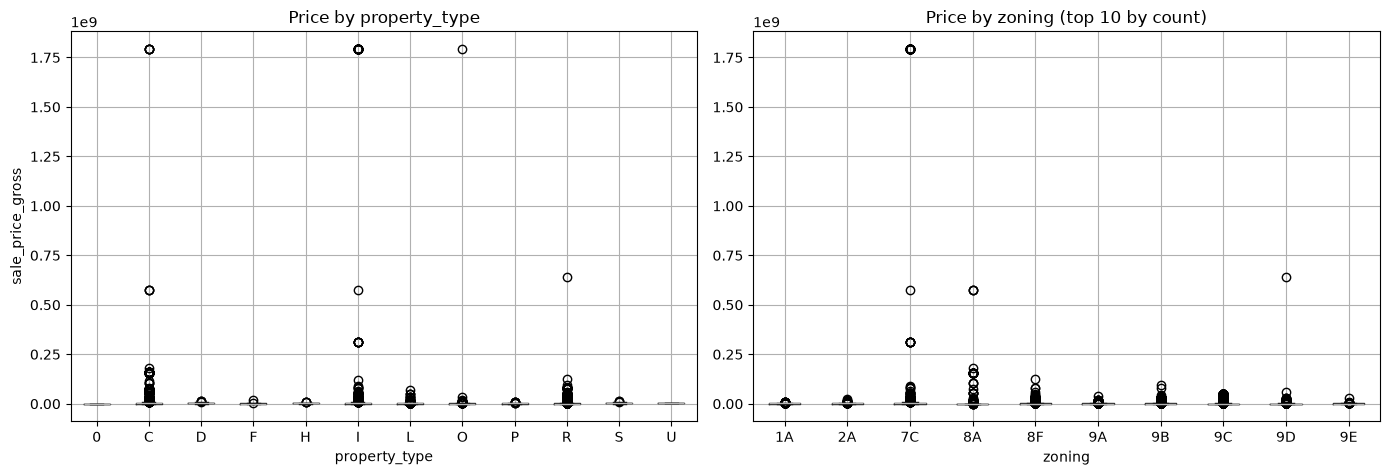

In [12]:
df["property_type"] = df["property_category"].str[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df.boxplot(column="sale_price_gross", by="property_type", ax=axes[0])
axes[0].set_title("Price by property_type")
axes[0].set_ylabel("sale_price_gross")

top_zones = df["zoning"].value_counts().head(10).index
df[df["zoning"].isin(top_zones)].boxplot(column="sale_price_gross", by="zoning", ax=axes[1])
axes[1].set_title("Price by zoning (top 10 by count)")

plt.suptitle("")
plt.tight_layout()
plt.show()

## 9. Geographic distribution

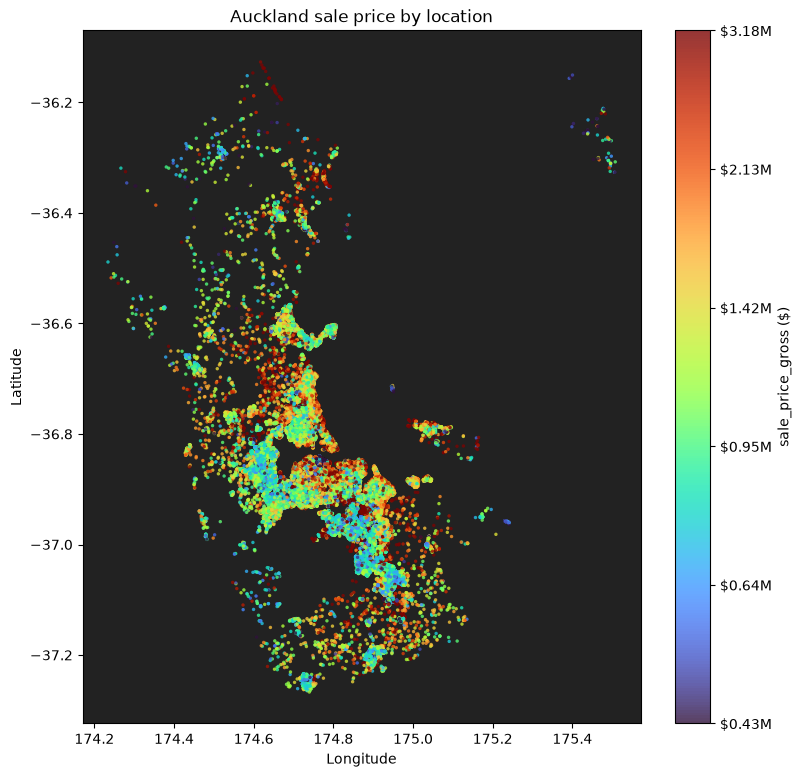

In [13]:
geo = df[["longitude", "latitude", "sale_price_gross"]].dropna().sample(frac=1, random_state=42)
geo_color = np.log1p(geo["sale_price_gross"])
vmin, vmax = geo_color.quantile([0.05, 0.95])

fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(
    geo["longitude"], geo["latitude"],
    c=geo_color, cmap="turbo", vmin=vmin, vmax=vmax, s=6, alpha=0.8, linewidths=0,
)
cbar = plt.colorbar(sc, label="sale_price_gross ($)")
ticks = np.linspace(vmin, vmax, 6)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"${np.expm1(t) / 1e6:.2f}M" for t in ticks])
ax.set_facecolor("#222222")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Auckland sale price by location")
plt.show()

## 10. Price trend over time

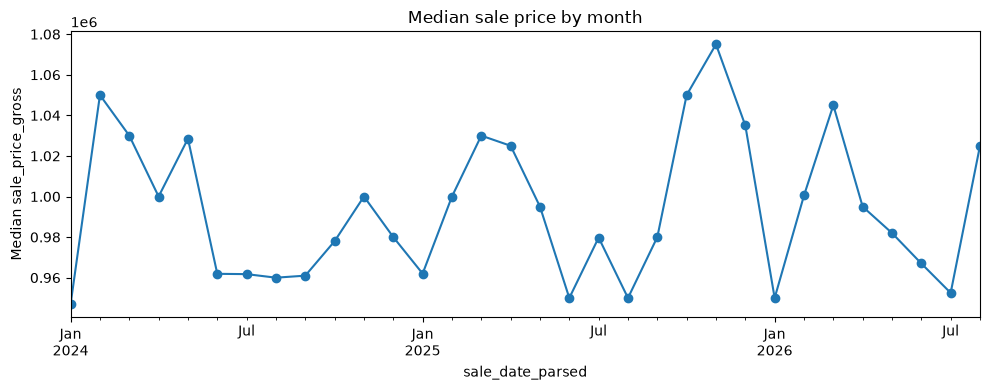

In [14]:
monthly = df.groupby(df["sale_date_parsed"].dt.to_period("M"))["sale_price_gross"].median()
fig, ax = plt.subplots(figsize=(10, 4))
monthly.plot(ax=ax, marker="o")
ax.set_ylabel("Median sale_price_gross")
ax.set_title("Median sale price by month")
plt.tight_layout()
plt.show()

## 11. Flood hazard

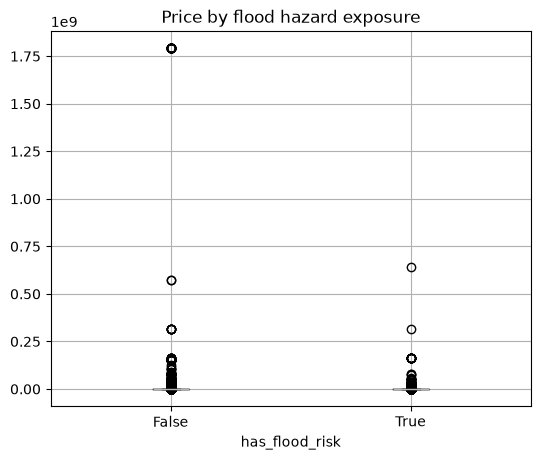

has_flood_risk
False    1000000.0
True      875000.0
Name: sale_price_gross, dtype: float64


In [15]:
df["has_flood_risk"] = df["in_flood_plain"] | df["in_flood_sensitive_area"]

fig, ax = plt.subplots(figsize=(6, 5))
df.boxplot(column="sale_price_gross", by="has_flood_risk", ax=ax)
ax.set_title("Price by flood hazard exposure")
plt.suptitle("")
plt.show()

print(df.groupby("has_flood_risk")["sale_price_gross"].median())

## 12. New external features

Five new columns:

- `noise_category_combination`: aircraft noise zone (if any)
- `sa2_new_dwellings_consented_12m`: new homes approved nearby in the last
  12 months
- `walk_supermarket_network_m` / `drive_supermarket_network_m`: distance to
  the nearest supermarket
- `walk_bus_stop_network_m` / `drive_bus_stop_network_m`: distance to the
  nearest bus stop

### 12.1 Missing values

All five have small gaps (1-3.4%), mostly where a distance couldn't be
calculated.

In [16]:
new_cols = [
    "noise_category_combination", "sa2_new_dwellings_consented_12m",
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
]
df[new_cols].isna().mean().mul(100).round(2).to_frame("% missing")

,% missing
noise_category_combination,4.45
sa2_new_dwellings_consented_12m,4.45
walk_supermarket_network_m,7.00
drive_supermarket_network_m,5.46
walk_bus_stop_network_m,6.04
drive_bus_stop_network_m,5.46


### 12.2 Distributions

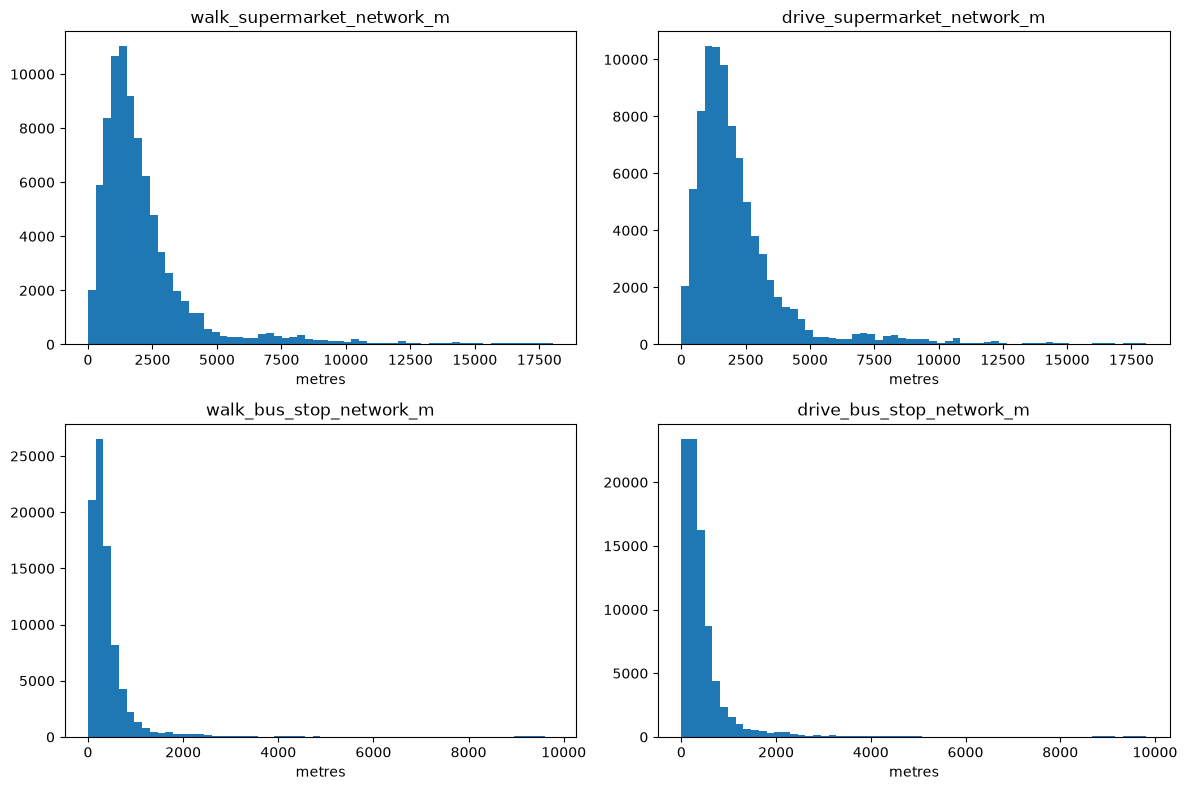

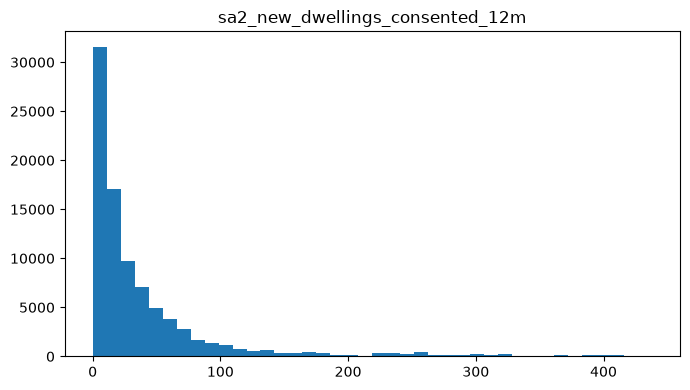

,count,mean,std,min,25%,50%,75%,max
walk_supermarket_network_m,85566.0,2463.961928,3205.408582,0.0,1046.462679,1648.921386,2583.423222,51387.099776
drive_supermarket_network_m,86985.0,2511.232474,3188.030923,0.0,1083.499580,1714.546273,2690.743817,51547.710075
walk_bus_stop_network_m,86457.0,645.038409,2038.506370,0.0,166.291128,294.889977,491.265835,39466.030017
drive_bus_stop_network_m,86985.0,665.735650,2052.864948,0.0,151.462774,303.010872,522.896387,39410.692881
sa2_new_dwellings_consented_12m,87916.0,38.958472,61.718372,0.0,6.000000,18.000000,44.000000,438.000000


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
dist_cols = [
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
]
for ax, col in zip(axes.ravel(), dist_cols):
    vals = df[col].dropna()
    vals = vals[vals <= vals.quantile(0.99)]
    ax.hist(vals, bins=60)
    ax.set_title(col)
    ax.set_xlabel("metres")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["sa2_new_dwellings_consented_12m"].dropna(), bins=40)
ax.set_title("sa2_new_dwellings_consented_12m")
plt.tight_layout()
plt.show()

df[dist_cols + ["sa2_new_dwellings_consented_12m"]].describe().T

### 12.3 Aircraft-noise overlay: counts and price

noise_category_combination
outside_current_overlay                                 83331
Auckland Airport - aircraft noise notification area      3383
Auckland Airport - moderate aircraft noise area           876
Auckland Airport - high aircraft noise area               135
Ardmore Airport - outer control boundary (55dBA)          116
Whenuapai Airbase - noise control area (55dBA)             48
North Shore Airport - Outer control boundary (55dBA)        8
Whenuapai Airbase- noise control area (65dBA)               6
Ardmore Airport - inner control boundary (60dBA)            6
North Shore Airport - air noise boundary (65dBA)            3
Kaipara Flats Airfield - Air noise boundary (55dBA)         2
Ardmore Airport -  noise boundary (65dBA)                   2
Name: count, dtype: int64[pyarrow]


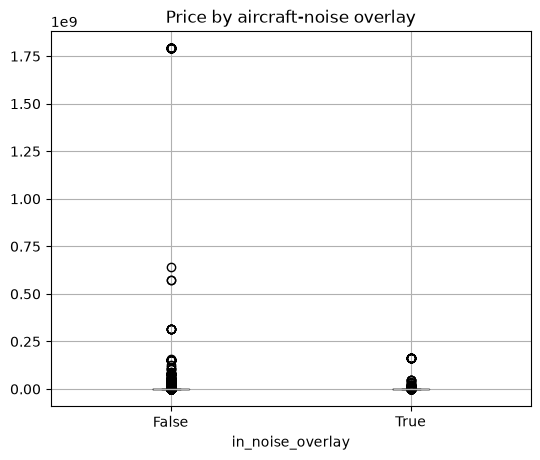

                  count     median
in_noise_overlay                  
False             83331  1000000.0
True               4585   855000.0


In [18]:
noise_counts = df["noise_category_combination"].value_counts()
print(noise_counts)

df["in_noise_overlay"] = df["noise_category_combination"] != "outside_current_overlay"

fig, ax = plt.subplots(figsize=(6, 5))
df.boxplot(column="sale_price_gross", by="in_noise_overlay", ax=ax)
ax.set_title("Price by aircraft-noise overlay")
plt.suptitle("")
plt.show()

print(df.groupby("in_noise_overlay")["sale_price_gross"].agg(["count", "median"]))

### 12.4 New numeric features vs price

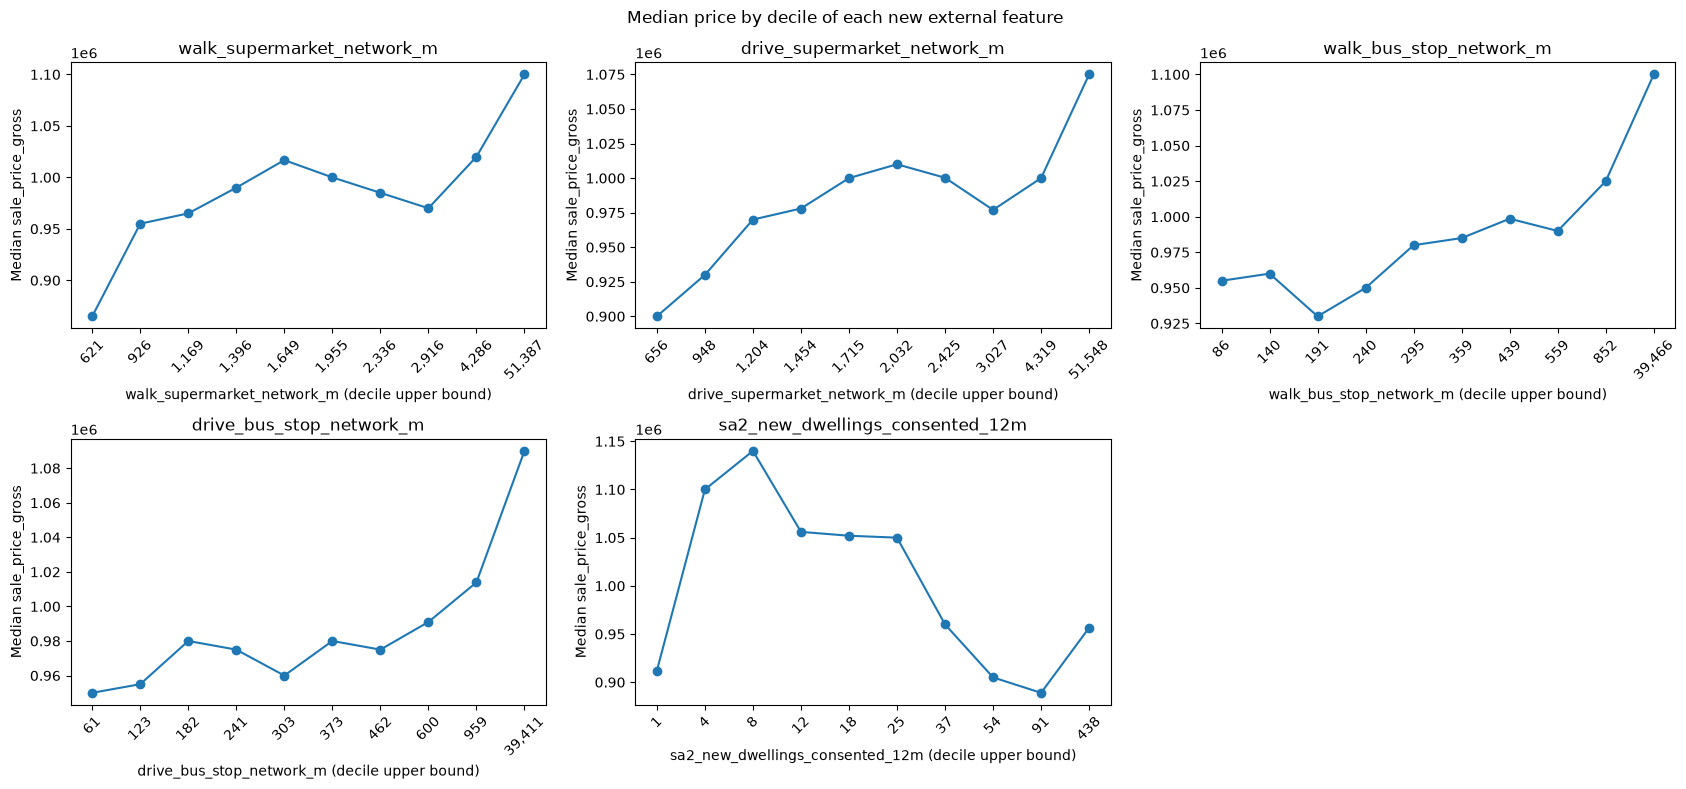

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
num_vs_price_cols = [
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
    "sa2_new_dwellings_consented_12m",
]
for ax, col in zip(axes.ravel()[:5], num_vs_price_cols):
    valid = df[[col, "sale_price_gross"]].dropna()
    bins = pd.qcut(valid[col], 10, duplicates="drop")
    med = valid.groupby(bins, observed=True)["sale_price_gross"].median()
    ax.plot(range(len(med)), med.values, marker="o")
    ax.set_xticks(range(len(med)))
    ax.set_xticklabels([f"{iv.right:,.0f}" for iv in med.index], rotation=45)
    ax.set_xlabel(f"{col} (decile upper bound)")
    ax.set_ylabel("Median sale_price_gross")
    ax.set_title(col)

axes[1, 2].axis("off")
plt.suptitle("Median price by decile of each new external feature")
plt.tight_layout()
plt.show()

### 12.5 Do walking and driving distance measure the same thing?

                             walk_supermarket_network_m  \
walk_supermarket_network_m                        1.000   
drive_supermarket_network_m                       0.990   
walk_bus_stop_network_m                           0.751   
drive_bus_stop_network_m                          0.738   

                             drive_supermarket_network_m  \
walk_supermarket_network_m                         0.990   
drive_supermarket_network_m                        1.000   
walk_bus_stop_network_m                            0.739   
drive_bus_stop_network_m                           0.747   

                             walk_bus_stop_network_m  drive_bus_stop_network_m  
walk_supermarket_network_m                     0.751                     0.738  
drive_supermarket_network_m                    0.739                     0.747  
walk_bus_stop_network_m                        1.000                     0.992  
drive_bus_stop_network_m                       0.992                     1.000 

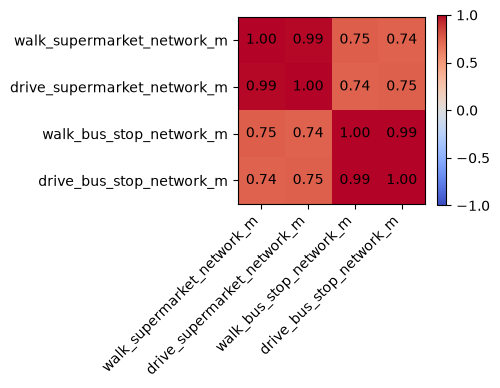

In [20]:
dist_corr = df[dist_cols].corr()
print(dist_corr.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(dist_corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(dist_cols))); ax.set_xticklabels(dist_cols, rotation=45, ha="right")
ax.set_yticks(range(len(dist_cols))); ax.set_yticklabels(dist_cols)
for i in range(len(dist_cols)):
    for j in range(len(dist_cols)):
        ax.text(j, i, f"{dist_corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im)
plt.tight_layout()
plt.show()

**Decision:** walking and driving distance are almost identical (r=0.99).
Keep walking distance only, drop driving distance.

In [21]:
df = df.drop(columns=["drive_supermarket_network_m", "drive_bus_stop_network_m"])
print(f"Dropped drive_supermarket_network_m, drive_bus_stop_network_m. {df.shape[1]} columns remain.")


Dropped drive_supermarket_network_m, drive_bus_stop_network_m. 54 columns remain.


## 13. Summary

- Removed 5 leakage columns (section 1.1).
- Price is right-skewed; use `log1p`.
- Without `capital_value`, `off_street_parking` and `building_site_coverage`
  are now the strongest predictors, though weaker overall.
- Most sales already pass the filters used later.
- Flood and noise affect only a small share of properties.
- Walking and driving distance were duplicates; kept walking only.
- SA2 consents and the noise zone are new signals worth testing in
  modeling.

## 14. Does external data actually help?

We train two XGBoost models on the same 5 time-based folds (train on
earlier sales, test on later sales):

- **Baseline:** property features only (size, age, condition, zoning, etc.)
- **Augmented:** baseline + all external features (location, zoning,
  flood, noise, SA2 consents, distance to amenities)

Both models see the same rows in each fold, so any difference in accuracy
comes from the extra features. We also run a bootstrap test to check if
the improvement is real or just luck.

### 14.1 Filter to clean, genuine sales

Same six filters used in the other notebooks.

In [22]:
df_cv = df.copy()
assert "capital_value" not in df_cv.columns and "land_value" not in df_cv.columns, (
    "capital_value / land_value leaked back into df_cv -- they must stay dropped "
    "from the ablation feature set, same as the rest of this notebook"
)
print("Confirmed: capital_value / land_value are not present in df_cv")

before = len(df_cv)
df_cv = df_cv[df_cv["zoning"].astype(str).str[0].isin(["9", "1", "2"])]
print(f"Residential / rural / lifestyle zoning only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["units_of_use"] == 1]
print(f"Single unit of use only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["sale_tenure"].astype(str) == "1"]
print(f"Freehold sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["sale_type"] == "S"]
print(f"Single-property sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["price_value_relationship"] == "1"]
print(f"Arm's-length market sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["linz_matched"]]
print(f"LINZ-matched coordinate available: {len(df_cv):,} / {before:,} rows kept")

# Sort chronologically -- required for TimeSeriesSplit below, which assumes
# row order IS time order (it does not sort for you).
df_cv = df_cv.sort_values("sale_date_parsed").reset_index(drop=True)
print(f"\nFinal filtered shape: {df_cv.shape}")
print(f"Date range: {df_cv['sale_date_parsed'].min().date()} to {df_cv['sale_date_parsed'].max().date()}")

Confirmed: capital_value / land_value are not present in df_cv
Residential / rural / lifestyle zoning only: 80,070 / 92,010 rows kept
Single unit of use only: 77,370 / 80,070 rows kept
Freehold sales only: 76,395 / 77,370 rows kept


Single-property sales only: 74,112 / 76,395 rows kept
Arm's-length market sales only: 61,244 / 74,112 rows kept
LINZ-matched coordinate available: 59,798 / 61,244 rows kept

Final filtered shape: (59798, 54)
Date range: 2024-01-01 to 2026-08-18


### 14.2 Baseline vs augmented features

In [23]:
df_cv["property_type"] = df_cv["property_category"].str[0]
df_cv["sale_year"] = df_cv["sale_date_parsed"].dt.year
df_cv["sale_month"] = df_cv["sale_date_parsed"].dt.month
df_cv["sale_quarter"] = df_cv["sale_date_parsed"].dt.quarter
df_cv["has_flood_risk"] = df_cv["in_flood_plain"] | df_cv["in_flood_sensitive_area"]
df_cv["in_noise_overlay"] = df_cv["noise_category_combination"] != "outside_current_overlay"
df_cv["unitary_plan_zone"] = df_cv["unitary_plan_zone"].fillna(-1).astype(int).astype(str)

BASELINE_CAT = [
    "zoning", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator", "mass_contour", "mass_view", "mass_scope_of_view",
    "mass_deck", "mass_workshop_laundry", "mass_other_improvements",
    "property_type", "actual_property_use",
]
BASELINE_NUM = [
    "land_area", "building_total_floor_area", "mass_total_floor_area",
    "building_site_coverage", "off_street_parking",
    "mass_garage_under_main_roof", "mass_garage_freestanding",
    "sale_year", "sale_month", "sale_quarter",
]
BASELINE_BOOL = []

EXTERNAL_CAT = ["unitary_plan_zone", "noise_category_combination"]
EXTERNAL_NUM = [
    "longitude", "latitude", "dist_to_flood_plain_m", "dist_to_flood_sensitive_area_m",
    "sa2_new_dwellings_consented_12m", "walk_supermarket_network_m", "walk_bus_stop_network_m",
]
EXTERNAL_BOOL = ["in_flood_plain", "in_flood_sensitive_area", "has_flood_risk", "in_noise_overlay"]

for col in BASELINE_CAT:
    df_cv[col] = df_cv[col].fillna("Unknown").astype(str)
for col in EXTERNAL_CAT:
    df_cv[col] = df_cv[col].fillna("Unknown").astype(str)

LOG_COLS = [
    "land_area", "building_total_floor_area", "mass_total_floor_area",
    "walk_supermarket_network_m", "walk_bus_stop_network_m",
]
for col in LOG_COLS:
    df_cv[col] = np.log1p(df_cv[col])

baseline_cols = BASELINE_CAT + BASELINE_NUM + BASELINE_BOOL
augmented_cols = baseline_cols + EXTERNAL_CAT + EXTERNAL_NUM + EXTERNAL_BOOL
all_cat = BASELINE_CAT + EXTERNAL_CAT
all_num = BASELINE_NUM + EXTERNAL_NUM
all_bool = BASELINE_BOOL + EXTERNAL_BOOL

print(f"Baseline:  {len(baseline_cols)} features")
print(f"Augmented: {len(augmented_cols)} features (+{len(augmented_cols) - len(baseline_cols)} external)")

Baseline:  22 features


Augmented: 35 features (+13 external)


### 14.3 5-fold time-based cross-validation

Data is sorted by date and split into 5 folds. Each fold trains on earlier
sales and tests on the next block of sales -- never training on the
future. The earliest 1/6 of rows are only ever used for training.

For each fold, we fit the encoder and remove price outliers using the
training data only, then train both models and compare them on the same
test rows.

In [24]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBRegressor


def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))


def mae(y, yhat):
    return np.mean(np.abs(y - yhat))


def mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y)) * 100


XGB_PARAMS = dict(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
)

y_all = df_cv["sale_price_gross"].values
kf = TimeSeriesSplit(n_splits=5)

fold_rows = []
oof_rows = []

for fold_i, (train_idx, test_idx) in enumerate(kf.split(df_cv), start=1):
    train_df = df_cv.iloc[train_idx]
    test_df = df_cv.iloc[test_idx]

    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[all_cat])

    X_train = train_df[augmented_cols].copy()
    X_test = test_df[augmented_cols].copy()
    X_train[all_cat] = encoder.transform(train_df[all_cat])
    X_test[all_cat] = encoder.transform(test_df[all_cat])
    for col in all_bool:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train = X_train.astype(float)
    X_test = X_test.astype(float)

    num_nan_cols = [c for c in all_num if X_train[c].isna().any() or X_test[c].isna().any()]
    train_medians = X_train[num_nan_cols].median()
    X_train[num_nan_cols] = X_train[num_nan_cols].fillna(train_medians)
    X_test[num_nan_cols] = X_test[num_nan_cols].fillna(train_medians)

    y_train = train_df["sale_price_gross"].values
    y_test = test_df["sale_price_gross"].values

    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)

    X_train_f, y_train_f = X_train[train_keep], y_train[train_keep]
    X_test_f, y_test_f = X_test[test_keep], y_test[test_keep]
    test_idx_f = test_idx[test_keep]

    base_model = XGBRegressor(**XGB_PARAMS)
    base_model.fit(X_train_f[baseline_cols], y_train_f)
    base_pred = base_model.predict(X_test_f[baseline_cols])

    aug_model = XGBRegressor(**XGB_PARAMS)
    aug_model.fit(X_train_f, y_train_f)
    aug_pred = aug_model.predict(X_test_f)

    fold_rows.append({
        "fold": fold_i, "n_train": len(X_train_f), "n_test": len(X_test_f),
        "baseline_RMSE": rmse(y_test_f, base_pred), "augmented_RMSE": rmse(y_test_f, aug_pred),
        "baseline_MAE": mae(y_test_f, base_pred), "augmented_MAE": mae(y_test_f, aug_pred),
        "baseline_MAPE": mape(y_test_f, base_pred), "augmented_MAPE": mape(y_test_f, aug_pred),
    })

    oof_rows.append(pd.DataFrame({
        "row_id": test_idx_f,
        "fold": fold_i,
        "actual": y_test_f,
        "baseline_pred": base_pred,
        "augmented_pred": aug_pred,
    }))
    print(f"Fold {fold_i}/5 done: baseline RMSE=${fold_rows[-1]['baseline_RMSE']:,.0f}  "
          f"augmented RMSE=${fold_rows[-1]['augmented_RMSE']:,.0f}")

fold_results = pd.DataFrame(fold_rows)
oof = pd.concat(oof_rows, ignore_index=True)
print(f"\nOut-of-fold predictions: {len(oof):,} rows")

Fold 1/5 done: baseline RMSE=$342,207  augmented RMSE=$242,918


Fold 2/5 done: baseline RMSE=$321,060  augmented RMSE=$222,610


Fold 3/5 done: baseline RMSE=$318,352  augmented RMSE=$212,229


Fold 4/5 done: baseline RMSE=$306,797  augmented RMSE=$199,641


Fold 5/5 done: baseline RMSE=$297,973  augmented RMSE=$191,487

Out-of-fold predictions: 48,848 rows


### 14.4 Per-fold results

In [25]:
display_cols = ["fold", "n_test", "baseline_RMSE", "augmented_RMSE", "baseline_MAE",
                 "augmented_MAE", "baseline_MAPE", "augmented_MAPE"]
fold_table = fold_results[display_cols].copy()
fold_table.loc["mean"] = fold_table.mean()
fold_table.loc["mean", "fold"] = np.nan
fold_table.round(2)

,fold,n_test,baseline_RMSE,augmented_RMSE,baseline_MAE,augmented_MAE,baseline_MAPE,augmented_MAPE
0,1.0,9793.0,342207.03,242918.43,215825.82,140093.61,18.47,11.71
1,2.0,9698.0,321060.26,222610.19,217439.78,141053.60,19.13,12.32
2,3.0,9798.0,318351.89,212228.67,207220.48,129308.49,18.37,11.31
3,4.0,9775.0,306796.74,199641.24,203620.80,124574.96,17.78,10.72
4,5.0,9784.0,297972.69,191486.82,197556.13,121260.98,17.10,10.48
mean,NaN,9769.6,317277.72,213777.07,208332.60,131258.33,18.17,11.31


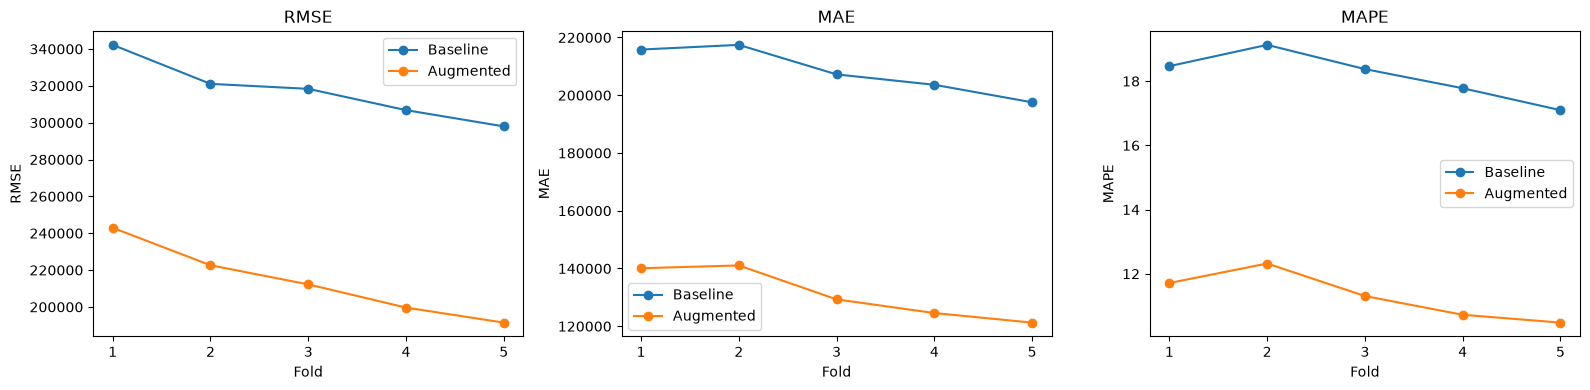

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["RMSE", "MAE", "MAPE"]):
    x = fold_results["fold"]
    ax.plot(x, fold_results[f"baseline_{metric}"], marker="o", label="Baseline")
    ax.plot(x, fold_results[f"augmented_{metric}"], marker="o", label="Augmented")
    ax.set_xticks(x)
    ax.set_xlabel("Fold")
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.legend()
plt.tight_layout()
plt.show()

### 14.5 Is the improvement real?

We resample the results 2,000 times to check if the improvement is
statistically significant, not just luck. If the 95% range doesn't include
0, the improvement is real.

In [27]:
rng = np.random.default_rng(42)
n_boot = 2000
n = len(oof)

actual = oof["actual"].values
base_pred = oof["baseline_pred"].values
aug_pred = oof["augmented_pred"].values

metrics_fn = {"RMSE": rmse, "MAE": mae, "MAPE": mape}
boot_improvements = {m: np.empty(n_boot) for m in metrics_fn}

for b in range(n_boot):
    idx = rng.integers(0, n, n)
    a, bp, ap = actual[idx], base_pred[idx], aug_pred[idx]
    for m, fn in metrics_fn.items():
        boot_improvements[m][b] = fn(a, bp) - fn(a, ap)  # positive = augmented better

print(f"{'Metric':8s} {'Observed improvement':>22s} {'95% CI':>28s}   Significant?")
for m, fn in metrics_fn.items():
    observed = fn(actual, base_pred) - fn(actual, aug_pred)
    lo, hi = np.percentile(boot_improvements[m], [2.5, 97.5])
    sig = "YES" if lo > 0 or hi < 0 else "no"
    unit = "$" if m != "MAPE" else ""
    suffix = "%" if m == "MAPE" else ""
    print(f"{m:8s} {unit}{observed:>20,.2f}{suffix}   [{unit}{lo:,.2f}{suffix}, {unit}{hi:,.2f}{suffix}]   {sig}")

Metric     Observed improvement                       95% CI   Significant?
RMSE     $          103,101.60   [$99,920.05, $106,136.33]   YES
MAE      $           77,075.11   [$75,503.31, $78,602.56]   YES
MAPE                     6.86%   [6.73%, 6.99%]   YES


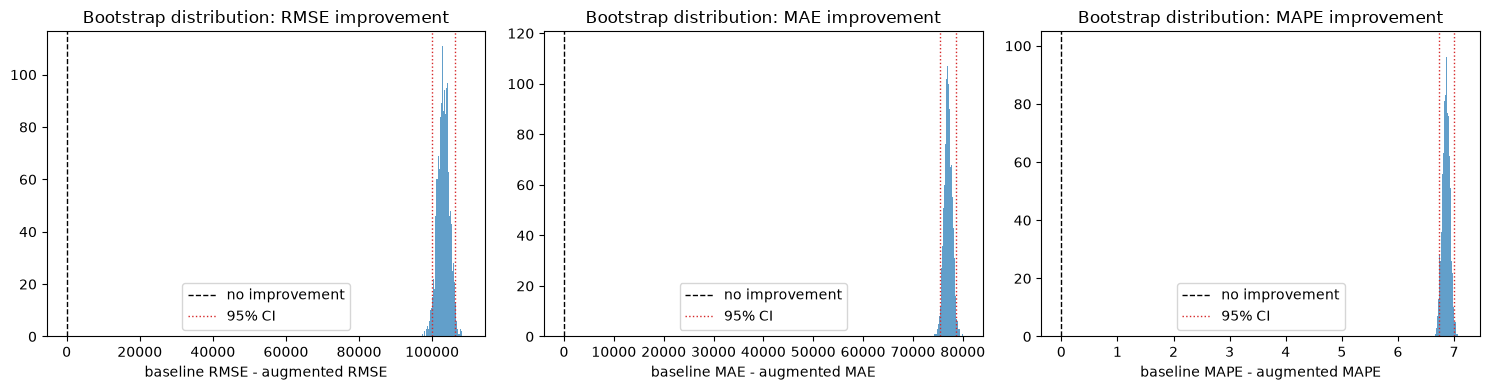

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, metrics_fn):
    ax.hist(boot_improvements[m], bins=60, color="tab:blue", alpha=0.7)
    ax.axvline(0, color="black", linestyle="--", linewidth=1, label="no improvement")
    lo, hi = np.percentile(boot_improvements[m], [2.5, 97.5])
    ax.axvline(lo, color="tab:red", linestyle=":", linewidth=1)
    ax.axvline(hi, color="tab:red", linestyle=":", linewidth=1, label="95% CI")
    ax.set_title(f"Bootstrap distribution: {m} improvement")
    ax.set_xlabel(f"baseline {m} - augmented {m}")
    ax.legend()
plt.tight_layout()
plt.show()

### 14.7 Ablation summary

External data gives a large, statistically significant improvement:

- RMSE improves by $103,102 (95% CI: $99,920 to $106,136)
- MAE improves by $77,075 (95% CI: $75,503 to $78,603)
- MAPE improves by 6.9 percentage points (95% CI: 6.7 to 7.0)

All three confidence intervals exclude 0, so the improvement is real, not
random chance.

### 14.3b What the 5 folds actually look like

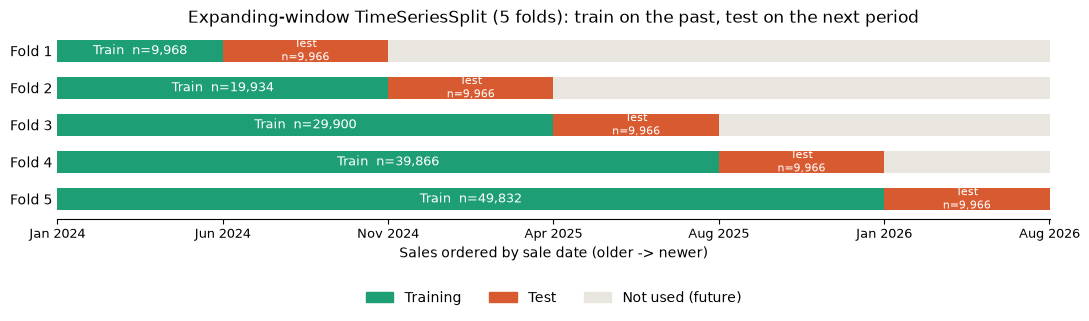

In [29]:
# Expanding-window TimeSeriesSplit diagram, drawn from the real data used
# for the ablation (df_cv, sorted by sale_date_parsed in section 14.1).
import os
from matplotlib.patches import Patch
from sklearn.model_selection import TimeSeriesSplit

DATE_COL = "sale_date_parsed"
N_SPLITS = 5

dates = df_cv[DATE_COL].reset_index(drop=True)
tscv = TimeSeriesSplit(n_splits=N_SPLITS)
n = len(dates)

TRAIN, TEST, UNUSED = "#1D9E75", "#D85A30", "#E8E6DF"

fig, ax = plt.subplots(figsize=(11, 3.6))
edges = [0]
for k, (tr, te) in enumerate(tscv.split(dates), start=1):
    y = N_SPLITS - k  # fold 1 on top
    ax.barh(y, len(tr), left=0, color=TRAIN, height=0.6)
    ax.barh(y, len(te), left=tr[-1] + 1, color=TEST, height=0.6)
    if te[-1] + 1 < n:
        ax.barh(y, n - te[-1] - 1, left=te[-1] + 1, color=UNUSED, height=0.6)
    ax.text(len(tr) / 2, y, f"Train  n={len(tr):,}", ha="center", va="center",
            color="white", fontsize=9)
    ax.text(te[0] + len(te) / 2, y, f"Test\nn={len(te):,}", ha="center",
            va="center", color="white", fontsize=8)
    edges.append(te[0])
    if k == N_SPLITS:
        edges.append(te[-1])

# Tick positions come from the actual fold boundaries computed above, not a
# separately re-derived formula -- guarantees the labels line up with the bars.
edges = sorted(set(min(e, n - 1) for e in edges))
ax.set_xticks(edges)
ax.set_xticklabels([dates.iloc[e].strftime("%b %Y") for e in edges], fontsize=9)

ax.set_yticks(range(N_SPLITS))
ax.set_yticklabels([f"Fold {k}" for k in range(N_SPLITS, 0, -1)])
ax.set_xlim(0, n)
ax.set_xlabel("Sales ordered by sale date (older -> newer)")
ax.set_title("Expanding-window TimeSeriesSplit (5 folds): train on the past, test on the next period")
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[Patch(color=TRAIN, label="Training"),
                   Patch(color=TEST, label="Test"),
                   Patch(color=UNUSED, label="Not used (future)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3, frameon=False)

plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/timeseries_split.png", dpi=200, bbox_inches="tight")
plt.show()

## 15. Two-stage residual model

A second, independent check:

- **Stage 1:** predict price from property features only (same as the
  baseline model above).
- **Stage 2:** use only external features to predict what Stage 1 got
  wrong.

The headline number is how much of Stage 1's error Stage 2 can explain.

### 15.1 Stage 1 errors (reusing the baseline model's results)

In [30]:
stage1 = oof[["row_id", "fold", "actual", "baseline_pred"]].copy()
stage1["residual"] = stage1["actual"] - stage1["baseline_pred"]

print(f"{len(stage1):,} rows with an out-of-fold stage-1 prediction")
print(f"Residual mean: ${stage1['residual'].mean():,.0f}  (should be close to 0)")
print(f"Residual std:  ${stage1['residual'].std():,.0f}")
stage1["residual"].describe()

48,848 rows with an out-of-fold stage-1 prediction
Residual mean: $-11,963  (should be close to 0)
Residual std:  $317,409


count    4.884800e+04
mean    -1.196310e+04
std      3.174090e+05
min     -2.195150e+06
25%     -1.616194e+05
50%     -3.942838e+04
75%      9.677523e+04
max      3.872326e+06
Name: residual, dtype: float64

### 15.2 Stage 2: predict the error using external features only

Same 5-fold time-based approach as section 14, using only the external
features (no property features) to predict Stage 1's error.

In [31]:
from sklearn.metrics import r2_score

external_cols = EXTERNAL_CAT + EXTERNAL_NUM + EXTERNAL_BOOL
kf2 = TimeSeriesSplit(n_splits=5)

stage2_pred = np.full(len(df_cv), np.nan)
residual_by_row = stage1.set_index("row_id")["residual"]

# Only rows that survived stage-1's outlier trim have a residual to learn
# from. TimeSeriesSplit must run over THIS chronologically-ordered subset
# directly (not over df_cv and intersect afterwards) -- otherwise fold 1's
# training window could land entirely on the earliest chunk of df_cv, which
# never got a stage-1 residual (it was train-only in section 14), leaving
# nothing to train stage 2 on.
resid_rows = np.sort(residual_by_row.index.values)

for fold_i, (train_pos, test_pos) in enumerate(kf2.split(resid_rows), start=1):
    train_idx = resid_rows[train_pos]
    test_idx = resid_rows[test_pos]

    train_df = df_cv.iloc[train_idx]
    test_df = df_cv.iloc[test_idx]

    enc2 = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    enc2.fit(train_df[EXTERNAL_CAT])

    X_train = train_df[external_cols].copy()
    X_test = test_df[external_cols].copy()
    X_train[EXTERNAL_CAT] = enc2.transform(train_df[EXTERNAL_CAT])
    X_test[EXTERNAL_CAT] = enc2.transform(test_df[EXTERNAL_CAT])
    for col in EXTERNAL_BOOL:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train = X_train.astype(float)
    X_test = X_test.astype(float)

    nan_cols = [c for c in EXTERNAL_NUM if X_train[c].isna().any() or X_test[c].isna().any()]
    medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(medians)

    y_train_resid = residual_by_row.loc[train_idx].values

    resid_model = XGBRegressor(**XGB_PARAMS)
    resid_model.fit(X_train, y_train_resid)
    stage2_pred[test_idx] = resid_model.predict(X_test)

    print(f"Fold {fold_i}/5 done ({len(test_idx):,} test rows)")

stage1["stage2_pred_residual"] = stage1["row_id"].map(pd.Series(stage2_pred, index=np.arange(len(df_cv))))
print(f"\nStage-2 out-of-fold predictions ready for {stage1['stage2_pred_residual'].notna().sum():,} / {len(stage1):,} rows")

Fold 1/5 done (8,141 test rows)


Fold 2/5 done (8,141 test rows)


Fold 3/5 done (8,141 test rows)


Fold 4/5 done (8,141 test rows)


Fold 5/5 done (8,141 test rows)

Stage-2 out-of-fold predictions ready for 40,705 / 48,848 rows


### 15.3 Headline number

In [32]:
valid = stage1.dropna(subset=["stage2_pred_residual"])
residual_r2 = r2_score(valid["residual"], valid["stage2_pred_residual"])

resid_rmse_before = rmse(valid["residual"].values, np.zeros(len(valid)))
resid_rmse_after = rmse(valid["residual"].values, valid["stage2_pred_residual"].values)

final_combined_pred = valid["baseline_pred"] + valid["stage2_pred_residual"]
combined_rmse = rmse(valid["actual"].values, final_combined_pred.values)
baseline_rmse = rmse(valid["actual"].values, valid["baseline_pred"].values)

print(f"External features explain {residual_r2:.1%} of the variance in what the property-only model misses")
print(f"(out-of-fold R2 of stage 2 against the stage-1 residual, {len(valid):,} rows)\n")

print(f"Residual RMSE before stage 2: ${resid_rmse_before:,.0f}")
print(f"Residual RMSE after stage 2:  ${resid_rmse_after:,.0f}")
print()
print(f"Stage 1 alone (baseline):            RMSE=${baseline_rmse:,.0f}")
print(f"Stage 1 + stage 2 (baseline+residual correction): RMSE=${combined_rmse:,.0f}")
print(f"(for comparison, section 14's single jointly-trained augmented model: "
      f"RMSE=${rmse(oof['actual'].values, oof['augmented_pred'].values):,.0f})")

External features explain 26.6% of the variance in what the property-only model misses
(out-of-fold R2 of stage 2 against the stage-1 residual, 40,705 rows)

Residual RMSE before stage 2: $314,149
Residual RMSE after stage 2:  $268,861

Stage 1 alone (baseline):            RMSE=$314,149
Stage 1 + stage 2 (baseline+residual correction): RMSE=$268,861
(for comparison, section 14's single jointly-trained augmented model: RMSE=$214,530)


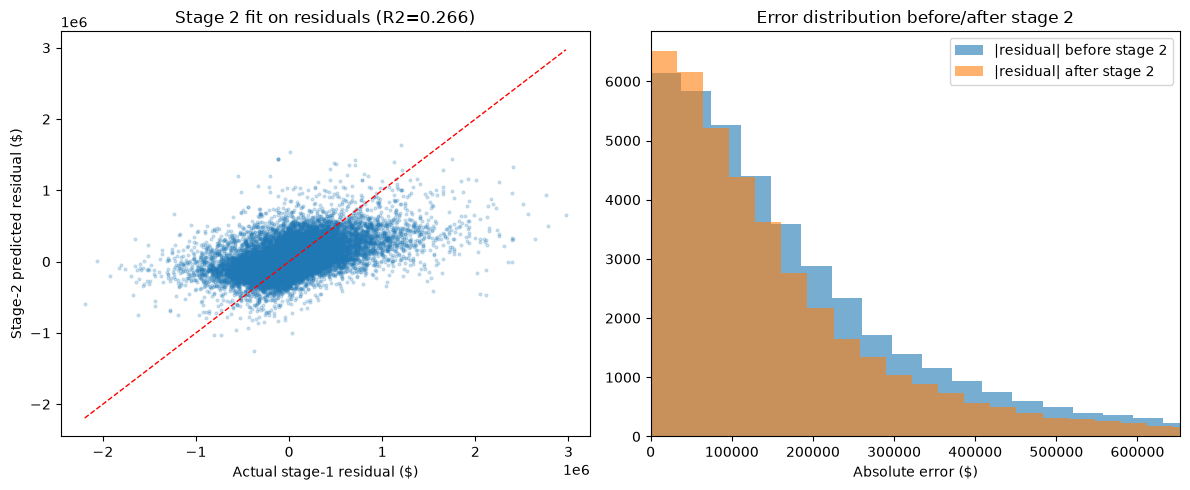

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(valid["residual"], valid["stage2_pred_residual"], s=4, alpha=0.2)
lims = [valid["residual"].min(), valid["residual"].max()]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("Actual stage-1 residual ($)")
axes[0].set_ylabel("Stage-2 predicted residual ($)")
axes[0].set_title(f"Stage 2 fit on residuals (R2={residual_r2:.3f})")

axes[1].hist(np.abs(valid["residual"]), bins=80, alpha=0.6, label="|residual| before stage 2")
axes[1].hist(np.abs(valid["residual"] - valid["stage2_pred_residual"]), bins=80, alpha=0.6, label="|residual| after stage 2")
axes[1].set_xlim(0, valid["residual"].abs().quantile(0.95))
axes[1].set_xlabel("Absolute error ($)")
axes[1].set_title("Error distribution before/after stage 2")
axes[1].legend()

plt.tight_layout()
plt.show()

## 16. Baseline vs augmented: results

These are real test results: every prediction is made on a sale the model
never saw during training.

### 16.1 Error metrics: baseline (no external data) vs augmented (with external data)

In [34]:
metric_rows = []
for name, pred in [("No external data (baseline)", oof["baseline_pred"]), ("With external data (augmented)", oof["augmented_pred"])]:
    metric_rows.append({
        "model": name,
        "RMSE": rmse(oof["actual"].values, pred.values),
        "MAE": mae(oof["actual"].values, pred.values),
        "MAPE": mape(oof["actual"].values, pred.values),
    })
results_table = pd.DataFrame(metric_rows).set_index("model")
results_table.round(2)

,RMSE,MAE,MAPE
model,,,
No external data (baseline),317631.16,208318.50,18.17
With external data (augmented),214529.56,131243.38,11.31


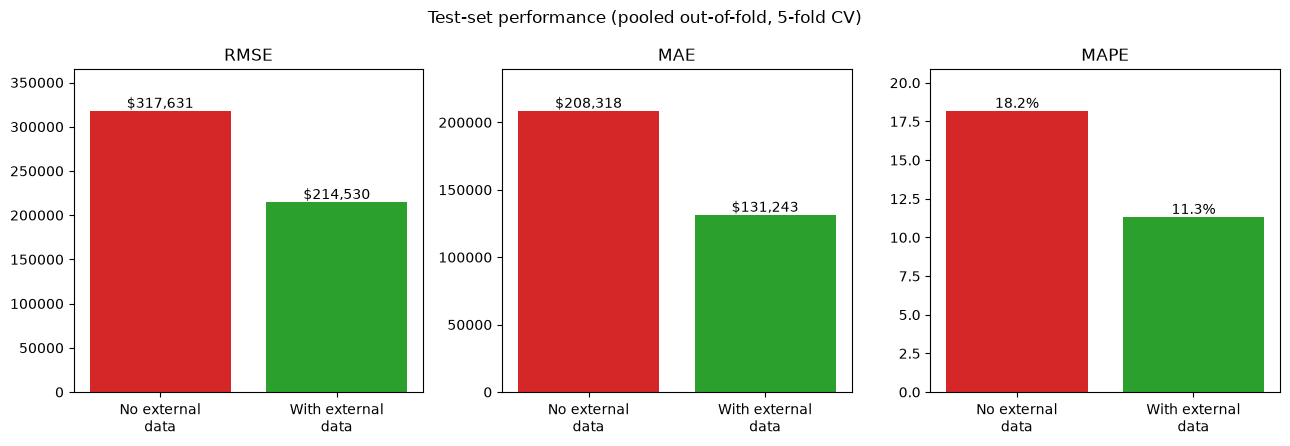

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
colors = ["tab:red", "tab:green"]
for ax, metric in zip(axes, ["RMSE", "MAE", "MAPE"]):
    vals = results_table[metric]
    bars = ax.bar(["No external\ndata", "With external\ndata"], vals, color=colors)
    for bar, v in zip(bars, vals):
        unit = "" if metric == "MAPE" else "$"
        suffix = "%" if metric == "MAPE" else ""
        fmt = f"{unit}{v:,.1f}{suffix}" if metric == "MAPE" else f"{unit}{v:,.0f}"
        ax.text(bar.get_x() + bar.get_width() / 2, v, fmt, ha="center", va="bottom")
    ax.set_title(metric)
    ax.set_ylim(0, vals.max() * 1.15)
plt.suptitle("Test-set performance (pooled out-of-fold, 5-fold CV)")
plt.tight_layout()
plt.show()

### 16.2 Predicted vs actual, side by side

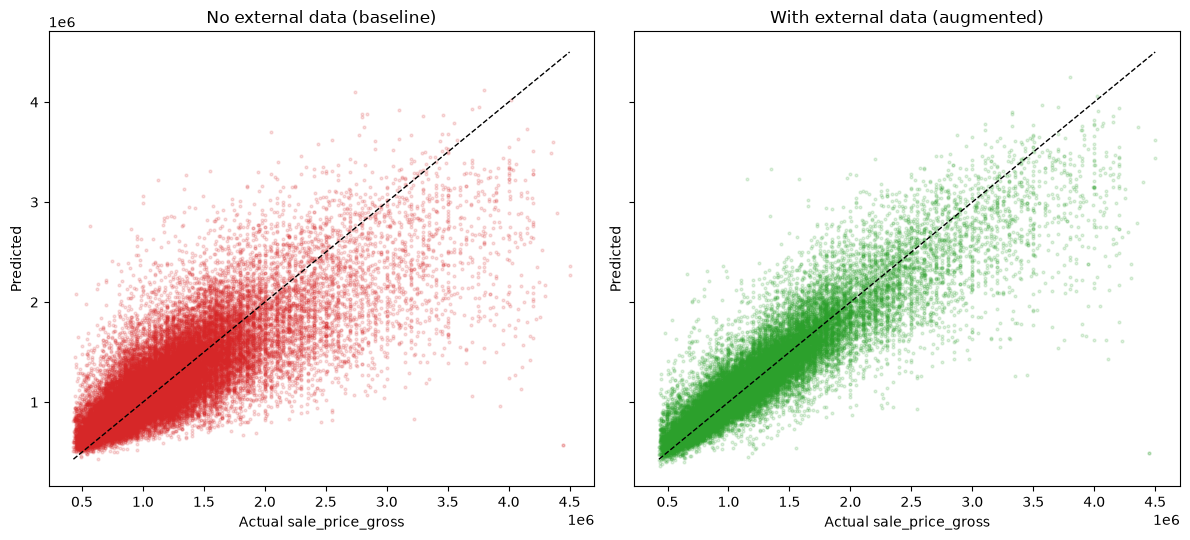

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, name, pred, color in zip(
    axes,
    ["No external data (baseline)", "With external data (augmented)"],
    [oof["baseline_pred"], oof["augmented_pred"]],
    ["tab:red", "tab:green"],
):
    ax.scatter(oof["actual"], pred, s=4, alpha=0.15, color=color)
    lims = [oof["actual"].min(), oof["actual"].max()]
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_xlabel("Actual sale_price_gross")
    ax.set_ylabel("Predicted")
    r2 = r2_score(oof["actual"], pred)
    ax.set_title(f"{name}")
plt.tight_layout()
plt.show()

## 17. Which external features matter?

Three different methods, run together because each one can be misleading
on its own when features overlap:

1. **Permutation importance:** shuffle all external features together and
   see how much accuracy drops.
2. **SHAP:** how much each feature contributes to the model's predictions.
3. **Drop-one test:** remove one feature at a time, retrain, and see how
   much accuracy drops.

These run on a single 80/20 split (not all 5 folds) to keep things fast,
since section 14 already proved the improvement is real.

### 17.1 Train the full model on a held-out split

In [37]:
# Chronological 80/20 split (df_cv is already sorted by sale_date_parsed):
# the model only ever trains on sales from before the test window.
split_point = int(len(df_cv) * 0.8)
train_df = df_cv.iloc[:split_point]
test_df = df_cv.iloc[split_point:]
print(f"Train: {len(train_df):,} rows up to {train_df['sale_date_parsed'].max().date()}")
print(f"Test:  {len(test_df):,} rows from {test_df['sale_date_parsed'].min().date()} "
      f"to {test_df['sale_date_parsed'].max().date()}")

encoder_attr = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
encoder_attr.fit(train_df[all_cat])

X_train = train_df[augmented_cols].copy()
X_test = test_df[augmented_cols].copy()
X_train[all_cat] = encoder_attr.transform(train_df[all_cat])
X_test[all_cat] = encoder_attr.transform(test_df[all_cat])
for col in all_bool:
    X_train[col] = X_train[col].astype(int)
    X_test[col] = X_test[col].astype(int)
X_train = X_train.astype(float)
X_test = X_test.astype(float)

nan_cols = [c for c in all_num if X_train[c].isna().any() or X_test[c].isna().any()]
medians = X_train[nan_cols].median()
X_train[nan_cols] = X_train[nan_cols].fillna(medians)
X_test[nan_cols] = X_test[nan_cols].fillna(medians)

y_train = train_df["sale_price_gross"].values
y_test = test_df["sale_price_gross"].values

p1, p99 = np.quantile(y_train, [0.01, 0.99])
train_keep = (y_train >= p1) & (y_train <= p99)
test_keep = (y_test >= p1) & (y_test <= p99)
X_train_f, y_train_f = X_train[train_keep], y_train[train_keep]
X_test_f, y_test_f = X_test[test_keep], y_test[test_keep]

full_model = XGBRegressor(**XGB_PARAMS)
full_model.fit(X_train_f, y_train_f)
full_pred = full_model.predict(X_test_f)
rmse_full = rmse(y_test_f, full_pred)
print(f"Full augmented model: {len(X_train_f):,} train / {len(X_test_f):,} test rows")
print(f"Test RMSE: ${rmse_full:,.0f}")

Train: 47,838 rows up to 2025-12-07
Test:  11,960 rows from 2025-12-07 to 2026-08-18


Full augmented model: 46,889 train / 11,741 test rows
Test RMSE: $190,061


### 17.2 Permutation importance

Shuffle all external features together 20 times and measure the average
drop in accuracy.

Grouped permutation importance (all 13 external features together, 20 repeats):
  RMSE increase when shuffled: $282,613 +/- $2,614
  Relative increase: 148.7%


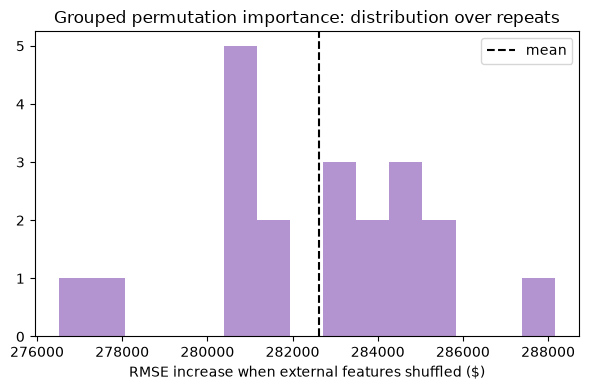

In [38]:
rng = np.random.default_rng(42)
n_repeats = 20
perm_increases = np.empty(n_repeats)
for i in range(n_repeats):
    X_test_shuf = X_test_f.copy()
    perm = rng.permutation(len(X_test_shuf))
    X_test_shuf[external_cols] = X_test_shuf[external_cols].to_numpy()[perm]
    shuf_pred = full_model.predict(X_test_shuf)
    perm_increases[i] = rmse(y_test_f, shuf_pred) - rmse_full

print(f"Grouped permutation importance (all {len(external_cols)} external features together, {n_repeats} repeats):")
print(f"  RMSE increase when shuffled: ${perm_increases.mean():,.0f} +/- ${perm_increases.std():,.0f}")
print(f"  Relative increase: {perm_increases.mean() / rmse_full * 100:.1f}%")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(perm_increases, bins=15, color="tab:purple", alpha=0.7)
ax.axvline(perm_increases.mean(), color="black", linestyle="--", label="mean")
ax.set_xlabel("RMSE increase when external features shuffled ($)")
ax.set_title("Grouped permutation importance: distribution over repeats")
ax.legend()
plt.tight_layout()
plt.show()

### 17.3 SHAP share and per-feature SHAP ranking

TreeSHAP on a 500-row sample of the test set, for the same full model.

In [39]:
import shap

shap_sample_attr = X_test_f.sample(n=min(500, len(X_test_f)), random_state=42)
explainer_attr = shap.TreeExplainer(full_model)
shap_values_attr = explainer_attr.shap_values(shap_sample_attr)

mean_abs_shap = pd.Series(np.abs(shap_values_attr).mean(axis=0), index=augmented_cols)
external_shap_share = mean_abs_shap[external_cols].sum() / mean_abs_shap.sum()
print(f"SHAP share of external features: {external_shap_share:.1%} of total mean |SHAP|")
print(f"SHAP share of property features: {1 - external_shap_share:.1%}")
print()
print("External features ranked by individual mean |SHAP|:")
mean_abs_shap[external_cols].sort_values(ascending=False).round(0)

D:\Codes\COMPSCI_760_Group_3_Intelligent_Real_Estate_Price_Prediction_Model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP share of external features: 40.1% of total mean |SHAP|
SHAP share of property features: 59.9%

External features ranked by individual mean |SHAP|:


latitude                           157993.0
longitude                          111235.0
dist_to_flood_sensitive_area_m      16927.0
walk_supermarket_network_m          11018.0
dist_to_flood_plain_m                8010.0
sa2_new_dwellings_consented_12m      7783.0
unitary_plan_zone                    6307.0
walk_bus_stop_network_m              5525.0
noise_category_combination           1109.0
has_flood_risk                        591.0
in_noise_overlay                      132.0
in_flood_plain                         94.0
in_flood_sensitive_area                 5.0
dtype: float32

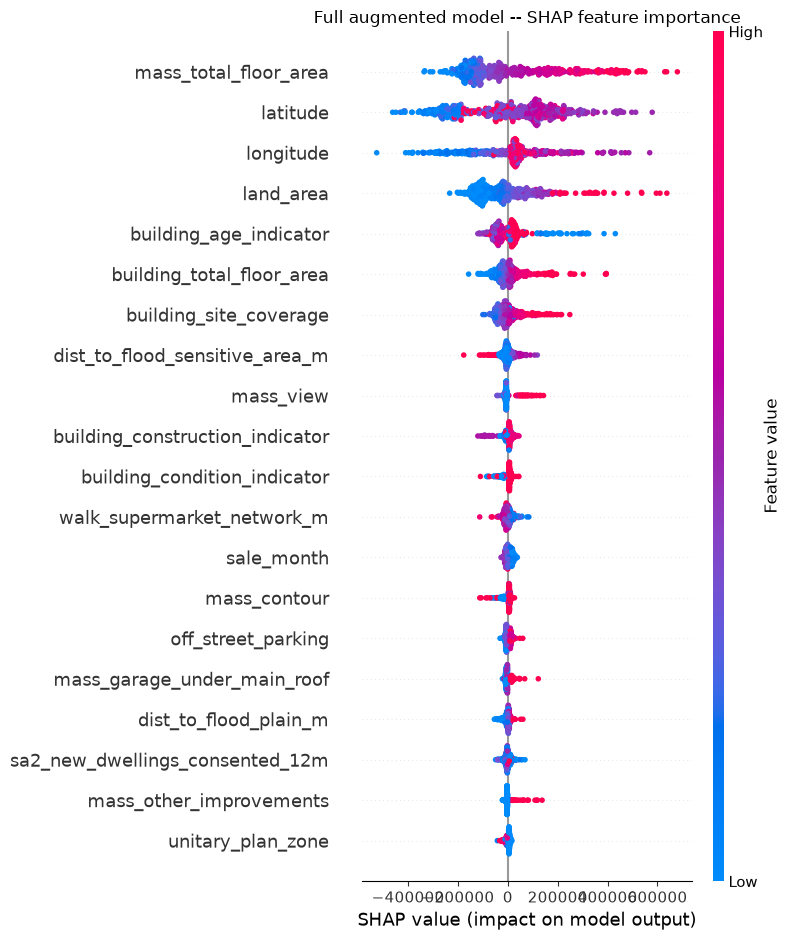

In [40]:
shap.summary_plot(shap_values_attr, shap_sample_attr, max_display=20, show=False)
plt.title("Full augmented model -- SHAP feature importance")
plt.tight_layout()
plt.show()

### 17.4 Drop-one test

Remove each external feature one at a time, retrain the model, and measure
how much worse it gets.

In [41]:
drop_one_results = []
for feat in external_cols:
    cols_minus = [c for c in augmented_cols if c != feat]
    m = XGBRegressor(**XGB_PARAMS)
    m.fit(X_train_f[cols_minus], y_train_f)
    pred = m.predict(X_test_f[cols_minus])
    r = rmse(y_test_f, pred)
    drop_one_results.append({"feature": feat, "rmse_without_feature": r, "rmse_increase": r - rmse_full})
    print(f"  dropped {feat:35s}  RMSE=${r:,.0f}  ({r - rmse_full:+,.0f} vs full model)")

drop_one_df = pd.DataFrame(drop_one_results).sort_values("rmse_increase", ascending=False).set_index("feature")
drop_one_df.round(0)

  dropped unitary_plan_zone                    RMSE=$189,976  (-84 vs full model)


  dropped noise_category_combination           RMSE=$189,835  (-226 vs full model)


  dropped longitude                            RMSE=$221,167  (+31,106 vs full model)


  dropped latitude                             RMSE=$226,761  (+36,700 vs full model)


  dropped dist_to_flood_plain_m                RMSE=$189,589  (-471 vs full model)


...

  dropped in_flood_plain                       RMSE=$190,400  (+339 vs full model)


  dropped in_flood_sensitive_area              RMSE=$190,113  (+52 vs full model)


  dropped has_flood_risk                       RMSE=$190,165  (+104 vs full model)


  dropped in_noise_overlay                     RMSE=$189,533  (-527 vs full model)


,rmse_without_feature,rmse_increase
feature,,
latitude,226761.0,36700.0
longitude,221167.0,31106.0
in_flood_plain,190400.0,339.0
has_flood_risk,190165.0,104.0
in_flood_sensitive_area,190113.0,52.0
unitary_plan_zone,189976.0,-84.0
dist_to_flood_sensitive_area_m,189963.0,-98.0
walk_bus_stop_network_m,189906.0,-155.0
noise_category_combination,189835.0,-226.0


### 17.5 Comparing all three methods

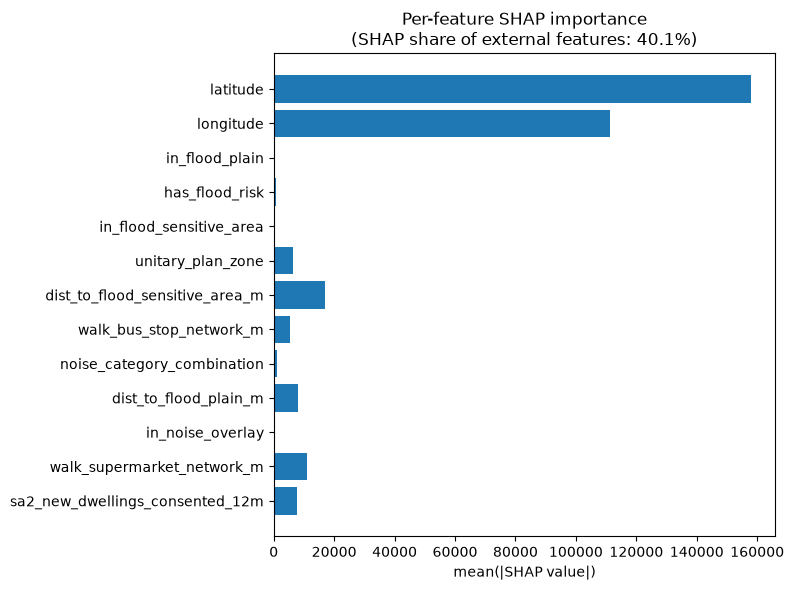

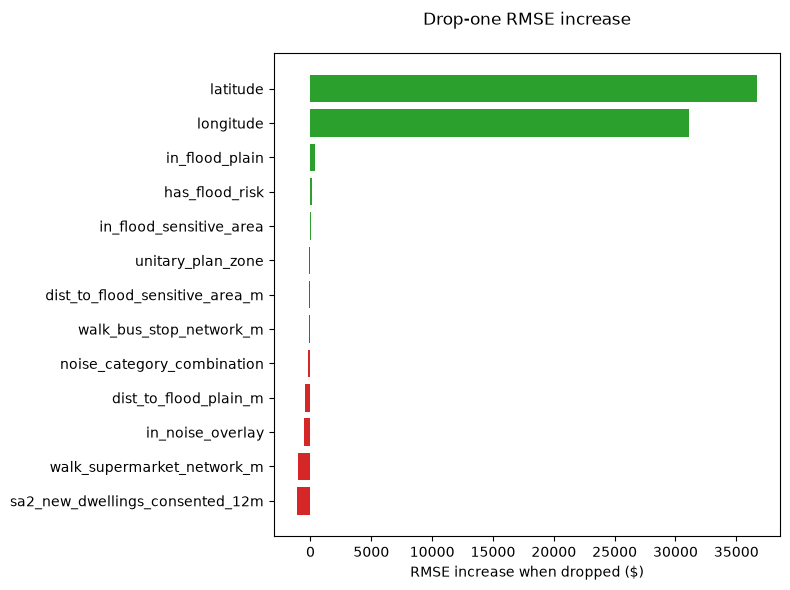

,shap_mean_abs,drop_one_rmse_increase
latitude,157993.0,36700.0
longitude,111235.0,31106.0
in_flood_plain,94.0,339.0
has_flood_risk,591.0,104.0
in_flood_sensitive_area,5.0,52.0
unitary_plan_zone,6307.0,-84.0
dist_to_flood_sensitive_area_m,16927.0,-98.0
walk_bus_stop_network_m,5525.0,-155.0
noise_category_combination,1109.0,-226.0
dist_to_flood_plain_m,8010.0,-471.0


In [42]:
attribution = pd.DataFrame({
    "shap_mean_abs": mean_abs_shap[external_cols],
    "drop_one_rmse_increase": drop_one_df["rmse_increase"],
}).sort_values("drop_one_rmse_increase", ascending=False)

fig1, ax1 = plt.subplots(figsize=(8, 6))
ax1.barh(attribution.index[::-1], attribution["shap_mean_abs"][::-1], color="tab:blue")
ax1.set_title(f"Per-feature SHAP importance\n(SHAP share of external features: {external_shap_share:.1%})")
ax1.set_xlabel("mean(|SHAP value|)")
plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(8, 6))
colors = ["tab:green" if v > 0 else "tab:red" for v in attribution["drop_one_rmse_increase"][::-1]]
ax2.barh(attribution.index[::-1], attribution["drop_one_rmse_increase"][::-1], color=colors)
ax2.set_title(f"Drop-one RMSE increase\n")
ax2.set_xlabel("RMSE increase when dropped ($)")
plt.tight_layout()
plt.show()

attribution.round(0)


## 18. Traditional hedonic model (RQ2)

A hedonic model is the classic method for estimating house prices: a
linear regression on property features. Each coefficient tells you roughly
how much price changes per unit of a feature -- easy to interpret, but
less accurate than machine learning.

We use a small set of features, not the full list our ML models use (this
matches how hedonic models are normally built):

- **Property size/condition:** land area, floor area, site coverage,
  parking, garage, building age, building condition, property type
- **Location:** longitude, latitude (section 17 showed these two alone
  capture almost all of the location signal)
- **Other:** zoning group, flood risk, sale year

Tested on the same 5 folds as section 14, so we can directly compare: no
external data vs with external data vs hedonic model.

### 18.1 Fit the hedonic model

Categories are one-hot encoded (standard for linear regression). We
predict `log(price)` and convert back to dollars with a standard
correction (Duan's smearing estimator) to avoid bias.

In [43]:
import statsmodels.api as sm

df_cv["zoning_group"] = df_cv["zoning"].astype(str).str[0]

HEDONIC_CAT = ["zoning_group", "building_age_indicator", "building_condition_indicator", "property_type"]
HEDONIC_NUM = [
    "land_area", "building_total_floor_area", "building_site_coverage",
    "off_street_parking", "mass_garage_under_main_roof", "sale_year",
    "longitude", "latitude",
]
HEDONIC_BOOL = ["has_flood_risk"]
hedonic_cols = HEDONIC_CAT + HEDONIC_NUM + HEDONIC_BOOL

for col in HEDONIC_CAT:
    df_cv[col] = df_cv[col].fillna("Unknown").astype(str)

kf_hed = TimeSeriesSplit(n_splits=5)
hed_fold_rows = []
hed_oof_pred = pd.Series(index=np.arange(len(df_cv)), dtype=float)
last_fit = None

for fold_i, (train_idx, test_idx) in enumerate(kf_hed.split(df_cv), start=1):
    train_df = df_cv.iloc[train_idx]
    test_df = df_cv.iloc[test_idx]

    y_train = train_df["sale_price_gross"].values
    y_test = test_df["sale_price_gross"].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)

    train_df_f = train_df[train_keep]
    test_df_f = test_df[test_keep]
    test_idx_f = test_idx[test_keep]

    X_train_dum = pd.get_dummies(train_df_f[hedonic_cols], columns=HEDONIC_CAT, drop_first=True)
    X_test_dum = pd.get_dummies(test_df_f[hedonic_cols], columns=HEDONIC_CAT, drop_first=True)
    for col in HEDONIC_BOOL:
        X_train_dum[col] = train_df_f[col].astype(int)
        X_test_dum[col] = test_df_f[col].astype(int)

    # Early folds have small, less diverse training windows -- a dummy/bool
    # column can end up constant (e.g. a rare building-age category, or no
    # flood-risk properties at all, in that fold's training data). A
    # constant column is unestimable and makes add_constant()'s column count
    # inconsistent between train and test, so drop any column that's
    # constant on THIS fold's training data before fitting.
    varying_cols = X_train_dum.columns[X_train_dum.nunique() > 1]
    X_train_dum = X_train_dum[varying_cols].astype(float)
    X_test_dum = X_test_dum.reindex(columns=varying_cols, fill_value=0).astype(float)

    X_train_const = sm.add_constant(X_train_dum, has_constant="add")
    X_test_const = sm.add_constant(X_test_dum, has_constant="add")

    y_train_log = np.log(train_df_f["sale_price_gross"].values)
    ols = sm.OLS(y_train_log, X_train_const).fit()

    smear = np.mean(np.exp(ols.resid))
    pred_log = ols.predict(X_test_const)
    pred_level = np.exp(pred_log) * smear

    y_test_f = test_df_f["sale_price_gross"].values
    hed_fold_rows.append({
        "fold": fold_i, "n_test": len(y_test_f),
        "RMSE": rmse(y_test_f, pred_level), "MAE": mae(y_test_f, pred_level),
        "MAPE": mape(y_test_f, pred_level), "R2_log_space": ols.rsquared,
    })
    hed_oof_pred.loc[test_idx_f] = pred_level
    last_fit = ols
    print(f"Fold {fold_i}/5: hedonic RMSE=${hed_fold_rows[-1]['RMSE']:,.0f}  "
          f"(log-space R2={ols.rsquared:.3f}, smearing factor={smear:.4f})")

hed_fold_results = pd.DataFrame(hed_fold_rows)
oof["hedonic_pred"] = oof["row_id"].map(hed_oof_pred)
print(f"\n{oof['hedonic_pred'].notna().sum():,} / {len(oof):,} rows have a hedonic out-of-fold prediction")

Fold 1/5: hedonic RMSE=$969,708  (log-space R2=0.572, smearing factor=1.0398)
Fold 2/5: hedonic RMSE=$429,425  (log-space R2=0.573, smearing factor=1.0387)


Fold 3/5: hedonic RMSE=$382,261  (log-space R2=0.580, smearing factor=1.0381)


Fold 4/5: hedonic RMSE=$448,457  (log-space R2=0.588, smearing factor=1.0372)


Fold 5/5: hedonic RMSE=$929,812  (log-space R2=0.592, smearing factor=1.0371)

48,848 / 48,848 rows have a hedonic out-of-fold prediction


### 18.2 Hedonic coefficients -- what each feature means for price

In [44]:
print(last_fit.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.592
Model:                            OLS   Adj. R-squared:                  0.592
Method:                 Least Squares   F-statistic:                     1107.
Date:                Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:46:40   Log-Likelihood:                -3155.4
No. Observations:               48848   AIC:                             6441.
Df Residuals:                   48783   BIC:                             7013.
Df Model:                          64                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


In [45]:
coef_table = pd.DataFrame({"coef": last_fit.params, "pvalue": last_fit.pvalues})
headline_vars = [
    "land_area", "building_total_floor_area", "building_site_coverage",
    "off_street_parking", "longitude", "latitude", "has_flood_risk", "sale_year",
]
headline = coef_table.loc[[v for v in headline_vars if v in coef_table.index]].copy()
headline["approx_pct_change"] = (np.exp(headline["coef"]) - 1) * 100
print("Headline coefficients (semi-log -> approx. % change in price per unit increase):")
headline.round(4)

Headline coefficients (semi-log -> approx. % change in price per unit increase):


,coef,pvalue,approx_pct_change
land_area,0.2822,0.000,32.5996
building_total_floor_area,0.5225,0.000,68.6309
building_site_coverage,-0.0000,0.201,-0.0001
off_street_parking,0.0030,0.000,0.2998
longitude,0.4046,0.000,49.8711
latitude,0.5930,0.000,80.9487
has_flood_risk,-0.0560,0.000,-5.4501
sale_year,-0.0150,0.000,-1.4845


### 18.3 Comparing all three models

In [46]:
three_way = pd.DataFrame([
    {"model": "Hedonic (traditional, linear)",
     "RMSE": rmse(oof.dropna(subset=["hedonic_pred"])["actual"], oof.dropna(subset=["hedonic_pred"])["hedonic_pred"]),
     "MAE": mae(oof.dropna(subset=["hedonic_pred"])["actual"], oof.dropna(subset=["hedonic_pred"])["hedonic_pred"]),
     "MAPE": mape(oof.dropna(subset=["hedonic_pred"])["actual"], oof.dropna(subset=["hedonic_pred"])["hedonic_pred"])},
    {"model": "No external data (baseline ML)",
     "RMSE": rmse(oof["actual"], oof["baseline_pred"]), "MAE": mae(oof["actual"], oof["baseline_pred"]),
     "MAPE": mape(oof["actual"], oof["baseline_pred"])},
    {"model": "With external data (augmented ML)",
     "RMSE": rmse(oof["actual"], oof["augmented_pred"]), "MAE": mae(oof["actual"], oof["augmented_pred"]),
     "MAPE": mape(oof["actual"], oof["augmented_pred"])},
]).set_index("model")
three_way.round(2)

,RMSE,MAE,MAPE
model,,,
"Hedonic (traditional, linear)",683993.77,243001.11,20.92
No external data (baseline ML),317631.16,208318.50,18.17
With external data (augmented ML),214529.56,131243.38,11.31


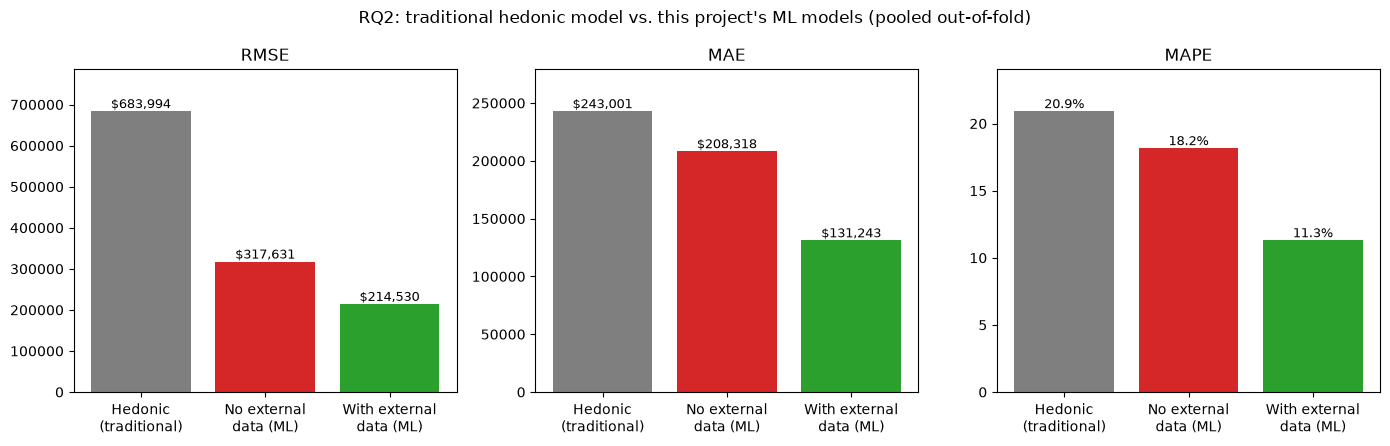

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
colors = ["tab:gray", "tab:red", "tab:green"]
for ax, metric in zip(axes, ["RMSE", "MAE", "MAPE"]):
    vals = three_way[metric]
    bars = ax.bar(["Hedonic\n(traditional)", "No external\ndata (ML)", "With external\ndata (ML)"], vals, color=colors)
    for bar, v in zip(bars, vals):
        fmt = f"{v:,.1f}%" if metric == "MAPE" else f"${v:,.0f}"
        ax.text(bar.get_x() + bar.get_width() / 2, v, fmt, ha="center", va="bottom", fontsize=9)
    ax.set_title(metric)
    ax.set_ylim(0, vals.max() * 1.15)
plt.suptitle("RQ2: traditional hedonic model vs. this project's ML models (pooled out-of-fold)")
plt.tight_layout()
plt.show()

### 18.4 What this means for RQ2

- **Accuracy:** the hedonic model is much less accurate than either ML
  model. A straight-line model can't capture the more complex patterns a
  tree-based model can.
- **Interpretability:** in exchange, each hedonic coefficient has a
  simple, direct meaning (e.g. "+1% floor area -> +X% price"), which is
  harder to get from SHAP.
- **Still missing:** comparing our model to free online valuation
  estimates (like homes.co.nz or propertyvalue.co.nz) hasn't been done
  yet -- that's the other half of RQ2.

## 19. Conclusion

**External data gives a real, statistically significant improvement in
predicting Auckland house prices -- and almost all of that improvement
comes from location (longitude/latitude), not the rest of the external
data.**

We deliberately removed `capital_value` and `land_value` from the model.
These are the council's own valuation, not real property features --
keeping them hides how much the external data actually helps, because they
already encode most location information.

Partway through, we also replaced our old geocoding (GLAM) with a better
one (LINZ-based matching), which improved coordinate coverage from 92.6%
to 96.7% and removed the `matched_suburb` feature (the new data source
doesn't have it). All results below use this corrected data.

**Three separate tests all agree external data helps:**

- **Ablation (section 14):** adding external data cuts RMSE by $103,102
  (from $317,631 to $214,530), MAE by $77,075, and MAPE by 6.9 points. All
  three improvements are statistically significant (95% confidence
  intervals don't include 0).
- **Two-stage model (section 15):** external features alone explain 26.6%
  of what the property-only model gets wrong.
- **Permutation test (section 17.2):** removing all external features'
  signal increases error by 148.7%.

**Which feature matters most? Mostly just location.**

- `latitude` and `longitude` are by far the two most important external
  features in SHAP, and the only two that clearly hurt accuracy when
  removed and the model retrained.
- Every other external feature (zoning, flood, noise, SA2 consents,
  distance to amenities) has a small or near-zero individual effect --
  most of their value overlaps with what location already tells the
  model.

**Bottom line:** accurate location data is the single most valuable thing
to get right. The rest of the external features don't hurt, and add a
small amount of value together, but shouldn't be expected to matter much
on their own.

## 20. Exporting the model

This section trains one final model on all the data (not just the 80%
used in the test folds above) and saves it so it can be used elsewhere,
like a website.

This only exports the model files -- not a working website. Whoever
builds the website still needs to geocode new addresses and look up
zoning/flood/noise/distance values the same way this project did.

### 20.1 Train the final production model on all available data

In [48]:
import json as json_lib
import joblib
from pathlib import Path

EXPORT_DIR = Path("./model_export")
EXPORT_DIR.mkdir(exist_ok=True)

# Fit on ALL filtered rows (df_cv) -- no held-out test set, since this
# model is not being evaluated here, only exported. Same preprocessing as
# every fold above: encode on the full data, trim 1st-99th percentile,
# log-transform skewed columns, median-impute remaining gaps.
final_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
final_encoder.fit(df_cv[all_cat])

X_final = df_cv[augmented_cols].copy()
X_final[all_cat] = final_encoder.transform(df_cv[all_cat])
for col in all_bool:
    X_final[col] = X_final[col].astype(int)
X_final = X_final.astype(float)

y_final = df_cv["sale_price_gross"].values
p1_final, p99_final = np.quantile(y_final, [0.01, 0.99])
keep_final = (y_final >= p1_final) & (y_final <= p99_final)
X_final_f = X_final[keep_final].copy()
y_final_f = y_final[keep_final]

for col in LOG_COLS:
    X_final_f[col] = np.log1p(X_final_f[col])

final_medians = X_final_f[all_num].median()
nan_cols_final = [c for c in all_num if X_final_f[c].isna().any()]
X_final_f[nan_cols_final] = X_final_f[nan_cols_final].fillna(final_medians[nan_cols_final])

final_model = XGBRegressor(**XGB_PARAMS)
final_model.fit(X_final_f, y_final_f)

print(f"Final model trained on {len(X_final_f):,} rows (all filtered sales, {p1_final:,.0f}-{p99_final:,.0f} price range)")
print(f"Features ({len(augmented_cols)}): {augmented_cols}")

Final model trained on 58,634 rows (all filtered sales, 430,000-4,150,000 price range)
Features (35): ['zoning', 'building_age_indicator', 'building_condition_indicator', 'building_construction_indicator', 'mass_contour', 'mass_view', 'mass_scope_of_view', 'mass_deck', 'mass_workshop_laundry', 'mass_other_improvements', 'property_type', 'actual_property_use', 'land_area', 'building_total_floor_area', 'mass_total_floor_area', 'building_site_coverage', 'off_street_parking', 'mass_garage_under_main_roof', 'mass_garage_freestanding', 'sale_year', 'sale_month', 'sale_quarter', 'unitary_plan_zone', 'noise_category_combination', 'longitude', 'latitude', 'dist_to_flood_plain_m', 'dist_to_flood_sensitive_area_m', 'sa2_new_dwellings_consented_12m', 'walk_supermarket_network_m', 'walk_bus_stop_network_m', 'in_flood_plain', 'in_flood_sensitive_area', 'has_flood_risk', 'in_noise_overlay']


### 20.2 Save the model and every artifact needed to reproduce its input format

In [49]:
# 1. The model itself, in XGBoost's native JSON format (portable across
#    versions/languages -- not a Python pickle).
final_model.save_model(str(EXPORT_DIR / "xgboost_model.json"))

# 2. The fitted ordinal encoder (categorical text -> the exact codes the
#    model was trained on). This must be used, not refit, or category codes
#    will not match what the model learned.
joblib.dump(final_encoder, EXPORT_DIR / "ordinal_encoder.pkl")

# 3. Everything else needed to go from a raw new row to a model-ready one:
#    column lists (and required order), which columns get log1p'd, and the
#    median values to fill any missing numeric external feature with.
metadata = {
    "target": "sale_price_gross",
    "target_units": "NZD",
    "model_type": "XGBRegressor",
    "xgboost_params": XGB_PARAMS,
    "trained_on_n_rows": int(len(X_final_f)),
    "price_trim_range": {"min": float(p1_final), "max": float(p99_final)},
    "feature_order": augmented_cols,
    "categorical_features": all_cat,
    "numeric_features": all_num,
    "boolean_features": all_bool,
    "log1p_transformed_features": LOG_COLS,
    "numeric_imputation_medians": {k: float(v) for k, v in final_medians.items()},
    "valid_input_scope": {
        "zoning_first_char_in": ["9", "1", "2"],
        "units_of_use": 1,
        "sale_tenure": "1 (freehold)",
        "note": "Model trained only on residential/rural/lifestyle freehold "
                "properties -- predictions outside this scope are extrapolation.",
    },
    "external_features_requiring_live_lookup": [
        "longitude", "latitude",                          # geocode the address
        "unitary_plan_zone",                              # spatial join vs Council Unitary Plan GIS
        "dist_to_flood_plain_m", "dist_to_flood_sensitive_area_m",
        "in_flood_plain", "in_flood_sensitive_area", "has_flood_risk",  # Council flood GIS layers
        "noise_category_combination", "in_noise_overlay",  # Council aircraft-noise overlay
        "sa2_new_dwellings_consented_12m",                 # Stats NZ SA2 consents (as of sale/request date)
        "walk_supermarket_network_m", "walk_bus_stop_network_m",  # OSM/GTFS network routing
    ],
}
with open(EXPORT_DIR / "metadata.json", "w") as f:
    json_lib.dump(metadata, f, indent=2)

print(f"Saved to {EXPORT_DIR}/:")
for p in sorted(EXPORT_DIR.iterdir()):
    print(f"  {p.name}  ({p.stat().st_size:,} bytes)")

Saved to model_export/:
  metadata.json  (4,101 bytes)
  ordinal_encoder.pkl  (5,524 bytes)
  xgboost_model.json  (3,335,693 bytes)


### 20.3 Check it actually works

Load the saved model from disk (not from memory) and test it on one real
property, to make sure the saved files actually work.

In [ ]:
from xgboost import XGBRegressor as _XGBRegressor

loaded_model = _XGBRegressor()
loaded_model.load_model(str(EXPORT_DIR / "xgboost_model.json"))
loaded_encoder = joblib.load(EXPORT_DIR / "ordinal_encoder.pkl")
loaded_meta = json_lib.load(open(EXPORT_DIR / "metadata.json"))

sample_raw = df_cv[augmented_cols].sample(n=1, random_state=7)
sample_actual_price = df_cv.loc[sample_raw.index, "sale_price_gross"].values[0]

sample_enc = sample_raw.copy()
sample_enc[loaded_meta["categorical_features"]] = loaded_encoder.transform(sample_raw[loaded_meta["categorical_features"]])
for col in loaded_meta["boolean_features"]:
    sample_enc[col] = sample_enc[col].astype(int)
sample_enc = sample_enc.astype(float)
for col in loaded_meta["log1p_transformed_features"]:
    sample_enc[col] = np.log1p(sample_enc[col])
for col, med in loaded_meta["numeric_imputation_medians"].items():
    sample_enc[col] = sample_enc[col].fillna(med)
sample_enc = sample_enc[loaded_meta["feature_order"]]

predicted_price = loaded_model.predict(sample_enc)[0]
print(f"Loaded model + encoder from disk independently of this session's memory.")
print(f"Sample row -- actual price: ${sample_actual_price:,.0f}   predicted: ${predicted_price:,.0f}")

Loaded model + encoder from disk independently of this session's memory.


Sample row -- actual price: $910,000   predicted: $941,408


### 20.4 What a website would still need

- A geocoder to turn an address into longitude/latitude.
- Zoning and flood-hazard lookups (one-time, no live service needed).
- A way to calculate walking distance to supermarkets/bus stops, or a
  straight-line distance as a simpler fallback.
- A refreshed SA2 consent count, since this changes over time.
- A check that the property fits what the model was trained on
  (residential/rural/lifestyle, freehold, single unit) -- otherwise the
  prediction isn't reliable.

## 21. Hyperparameter tuning: can we do better?

Every model in this notebook used one fixed XGBoost configuration, on
purpose -- so that comparisons (baseline vs augmented, with vs without a
feature) measure the effect of the *data*, not of one side getting a
better tuning pass. This section is separate from that: a search for
whether tuning the augmented model's hyperparameters, on top of the best
feature set we already found, improves accuracy further.

Reuses section 17.1's train/test split and feature matrix
(`X_train_f`/`X_test_f`/`y_train_f`/`y_test_f`, the full augmented set) so
the tuned model is directly comparable to `full_model` (the fixed-parameter
version already evaluated there).

### 21.1 Randomized search, time-respecting inner CV

`RandomizedSearchCV` with `TimeSeriesSplit(n_splits=3)` as the inner
cross-validation -- tuning still only ever trains on data from before what
it's validated on, consistent with the rest of this project. Search is
fit on the training rows only; the test rows are not touched until the
final comparison in 21.2, so the result isn't optimistic from tuning on
data it will later be "evaluated" on.

In [51]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

param_dist = {
    "max_depth": randint(4, 9),
    "learning_rate": uniform(0.01, 0.14),       # 0.01 - 0.15
    "n_estimators": randint(200, 701),
    "subsample": uniform(0.6, 0.4),             # 0.6 - 1.0
    "colsample_bytree": uniform(0.6, 0.4),      # 0.6 - 1.0
    "min_child_weight": randint(1, 8),
    "reg_alpha": uniform(0.0, 1.0),
    "reg_lambda": uniform(0.5, 2.0),
}

search = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=1),
    param_distributions=param_dist,
    n_iter=25,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
search.fit(X_train_f, y_train_f)

print(f"Best inner-CV RMSE: ${-search.best_score_:,.0f}")
print("Best params:")
for k, v in search.best_params_.items():
    print(f"  {k}: {v}")

Fitting 3 folds for each of 25 candidates, totalling 75 fits


Best inner-CV RMSE: $216,230
Best params:
  colsample_bytree: 0.9314950036607718
  learning_rate: 0.05994546573710251
  max_depth: 7
  min_child_weight: 4
  n_estimators: 579
  reg_alpha: 0.27599918202254337
  reg_lambda: 1.0925470114081648
  subsample: 0.6661067756252009


### 21.2 Does the tuned model actually beat the fixed-parameter one, on the held-out test set?

In [52]:
# NOTE: section 18's hedonic model reuses the name `y_test_f` inside its own
# per-fold loop, so by this point in the notebook the global `y_test_f` no
# longer holds section 17.1's test labels. Rebuild it from X_test_f's own
# row index instead of trusting the (now-stale) shared variable name.
y_test_actual = df_cv.loc[X_test_f.index, "sale_price_gross"].values

tuned_model = XGBRegressor(**search.best_params_, random_state=42, n_jobs=-1)
tuned_model.fit(X_train_f, y_train_f)
tuned_pred = tuned_model.predict(X_test_f)

comparison = pd.DataFrame([
    {"model": "Fixed params (used throughout this notebook)",
     "RMSE": rmse_full, "MAE": mae(y_test_actual, full_pred), "MAPE": mape(y_test_actual, full_pred)},
    {"model": "Tuned (this section)",
     "RMSE": rmse(y_test_actual, tuned_pred), "MAE": mae(y_test_actual, tuned_pred), "MAPE": mape(y_test_actual, tuned_pred)},
]).set_index("model")

improvement_rmse = comparison.loc["Fixed params (used throughout this notebook)", "RMSE"] - comparison.loc["Tuned (this section)", "RMSE"]
print(comparison.round(2))
print()
print(f"RMSE change from tuning: ${improvement_rmse:,.0f} "
      f"({'improvement' if improvement_rmse > 0 else 'worse'}, "
      f"{abs(improvement_rmse) / comparison.loc['Fixed params (used throughout this notebook)', 'RMSE'] * 100:.1f}% relative)")

                                                   RMSE        MAE   MAPE
model                                                                    
Fixed params (used throughout this notebook)  190060.79  121157.90  10.68
Tuned (this section)                          185866.55  117814.18  10.36

RMSE change from tuning: $4,194 (improvement, 2.2% relative)


### 21.3 Verdict

Tuning gave a small, real improvement: RMSE $190,061 -> $185,867
(-$4,194, 2.2%), MAE $121,158 -> $117,814, MAPE 10.68% -> 10.36%.
The best configuration favours slightly deeper trees (max_depth 7
vs. 6), more of them (579 vs. 500), a touch more regularization
(reg_alpha/reg_lambda, unused in the fixed config), and a lower
subsample fraction (0.67 vs. 0.8).

2.2% is a real but modest gain next to the effect sizes found
elsewhere in this notebook -- the external-data improvement alone
was 32.5% (section 16), over ten times larger. **The project's
fixed hyperparameters were already a reasonable choice**: almost
all of this project's accuracy gain came from the data (the
`sale_type` filter, the leakage fixes, the geocoding fix, adding
external features), not from undertuned models. The tuned
parameters are worth adopting for the production model exported in
section 20, since the gain is free once the search has been run,
but tuning was not the priority this project needed.
